<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ IFEST 2026 Final DAC: Peringatan Dini Water Stress Sub-DAS ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Memprediksi kekurangan air bulan depan pada sub-DAS (HUC12) Amerika Serikat dari riwayat water budget bulanan</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **IndomaretLabtekV**

- Riantama Putra
- Athilla Zaidan Zidna Fann
- Nicholas Wise Saragih Sumbayak

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Pemahaman Masalah**](#3)
4. [**Prapemrosesan**](#4)
5. [**Fitting untuk Explainable AI**](#5)
6. [**Analisis Data Eksploratif**](#6)
7. [**Rekayasa Fitur**](#7)
8. [**Pemodelan**](#8)
9. [**Evaluasi**](#9)
10. [**Inferensi dan Submisi**](#10)
11. [**Pasca-Analisis**](#11)
12. [**Daftar Pustaka**](#12)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Ketersediaan air pada sebuah sub-DAS berubah setiap bulan mengikuti pasokan hidrologis dan pemakaian air. Ketika pasokan turun jauh di bawah kondisi normalnya, wilayah tersebut mengalami *water stress*. Pada kompetisi **IFEST 2026 Final Data Analysis Competition**, peserta diminta membangun model *machine learning* yang memberi peringatan dini potensi *water stress* pada **bulan berikutnya** untuk setiap sub-DAS (HUC12) di Amerika Serikat, berdasarkan riwayat *water budget* bulanan periode 2000 sampai 2020.

- **Tugas**: klasifikasi biner, apakah sub-DAS mengalami *water stress* pada bulan berikutnya
- **Keluaran**: skor risiko kontinu 0 sampai 1 untuk setiap baris *test* (`row_id`, `label`)
- **Metrik**: *Average Precision* (AP)
- **Platform**: Kaggle Notebook, GPU T4 x2

---

## Metrik

***Average Precision* (AP)** merangkum kurva *precision-recall* sebagai rata-rata *precision* pada setiap *threshold*, dibobot oleh kenaikan *recall*. Kelas positif hanya sekitar 20 persen, sehingga AP menilai kualitas urutan skor pada kelas minoritas dan bukan akurasi keseluruhan. AP dari tebakan acak sama dengan proporsi positif, yaitu sekitar 0.204.

$$\text{AP} = \sum_n (R_n - R_{n-1})\,P_n$$

---

## Dataset

*Dataset* berisi panel sub-DAS x *forecast origin*. Setiap baris memuat jendela 12 bulan terakhir untuk enam keluarga aliran, klimatologi pasokan, karakteristik statis, dan tautan jaringan sungai. *Train* berisi 378,780 baris dari 2,196 sub-DAS dan 168 *origin*, sedangkan *test* berisi 11,928 baris dari 2,982 sub-DAS dan 4 *origin*. Sebanyak 26 persen sub-DAS *test* tidak pernah muncul di *train*. Data sengaja dikotori oleh panitia (format angka campur aduk, *sentinel*, nilai hilang, *spike*, duplikat, dan kolom jebakan).

**Atribut**

1.  `id`, `to_id`                     : ID HUC12 anonim dan HUC hilir (jaringan sungai)
2.  `origin_id`, `month`              : ID acak *forecast origin* dan bulan kalender *origin*
3.  `inc_aream2`, `cum_aream2`        : Luas inkremental dan kumulatif catchment (m2)
4.  `pop_*`                           : Populasi sensus 2000, 2010, 2020, dan ACS 2020
5.  `q_bf_inc_m3_lag0..11`            : *Baseflow* inkremental 12 bulan terakhir (m3)
6.  `q_qf_inc_m3_lag0..11`            : *Quickflow* inkremental 12 bulan terakhir (m3)
7.  `q_ws_cum_m3_lag0..11`            : Pasokan air kumulatif (*gross cumulative water supply*) 12 bulan terakhir (m3)
8.  `q_ir/th/ps_wd_inc_m3_lag0..11`   : Pengambilan air irigasi, *thermoelectric*, dan *public supply* (m3)
9.  `clim_median_now/next`            : Median klimatologi pasokan bulan *origin* dan bulan target (m3)
10. `aux_*`                           : 17 kolom tambahan (noise, konstanta, salinan satuan, teks acak)

**Target**
 `label` : 1 jika bulan target mengalami *water stress* (0: aman, 1: *water stress*)

---

## Pendekatan: *Physics-Informed Gradient Boosting* dengan Validasi yang Meniru Test

Rekayasa balik label menunjukkan bahwa `label = 1` tepat ketika pasokan bulan depan tidak lebih dari 0.6 kali median klimatologinya (cocok 99.99 persen, sama dengan definisi *Surface Water Supply and Use Index* USGS). Masalah ini karenanya diperlakukan sebagai *forecasting* anomali pasokan satu bulan ke depan, dan semua fitur dinyatakan sebagai rasio terhadap klimatologi.

Dua temuan forensik menentukan desain *pipeline*. Pertama, setiap sub-DAS *test* dikalikan faktor acak 0.25 sampai 4 kali, sehingga hanya fitur rasio di dalam baris yang aman dipakai. Kedua, *test* berada di masa depan (2015 sampai 2020) dan 26 persen barisnya adalah 47 basin utuh yang tidak ada di *train*, sehingga validasi harus menahan blok waktu **dan** basin utuh sekaligus.

```
raw CSV (string kotor)
    |
    +-- parsing angka dan bulan -> dedup -> rekonstruksi timeline
    +-- perbaikan korupsi (nol, spike, badai, identitas water budget, neraca jaringan sungai NNLS)
    +-- koreksi skala klimatologi 1000x
         |
    fitur rasio: anomali 12 lag, margin ke ambang 0.6, skenario kering,
    durasi kekeringan, jaringan sungai, peluang transisi (~55 fitur)
         |
    LightGBM (V8 dan tuned) + LightGBM DART + XGBoost + CatBoost, hibrida riwayat
         |
    rata-rata rank 5 keluarga -> skor risiko 0-1
```

Ringkasan iterasi yang membentuk notebook ini (public score hanya dipakai untuk memilih versi, tidak pernah masuk ke perhitungan prediksi):

| Versi | Perubahan utama | Public |
|---|---|---|
| V1 | *Pipeline* lengkap, klimatologi gabungan *train* dan *test* | 0.423 |
| V2 | Temuan skala acak per sub-DAS, klimatologi per split, fitur bebas skala | 0.720 |
| V3-V5 | Peluang transisi, model hibrida, tuning, rata-rata 3 seed | 0.752-0.7552 |
| V8 | Holdout basin utuh di CV, fitur dinamika catchment dicabut | 0.75548 |
| V15, V17 | Ensemble lima keluarga, dipilih lewat validasi tiga split basin | 0.754 |

---

## Kepatuhan terhadap Aturan Kompetisi

| Aturan | Penerapan pada notebook ini |
|---|---|
| 1. Tanpa *dataset* eksternal | Hanya `train.csv`, `test_public.csv`, dan `sample_submission.csv`. Pengetahuan domain (definisi SUI USGS, awal data *thermoelectric* 2008) hanya dipakai untuk menafsirkan temuan, tidak dimuat sebagai data |
| 2-3. Tanpa model *pretrained*, dilatih dari nol | Seluruh model adalah *gradient boosting* (LightGBM, XGBoost, CatBoost) yang dilatih dari nol di notebook ini |
| 4. Tanpa AutoML penuh | Fitur, skema validasi, dan ensemble dirancang manual |
| 5. HPO diperbolehkan | Optuna dijalankan secara lokal pada skema validasi yang meniru *test*; hasilnya ditulis tetap di `Settings` |
| 6-7. *Seed* dikunci | `seed_everything` mengunci `random`, `PYTHONHASHSEED`, dan NumPy di awal; *seed* yang sama diteruskan ke LightGBM, XGBoost, CatBoost, dan scikit-learn. PyTorch dan TensorFlow tidak dipakai |
| 8. Nama berkas | `Final_DAC2026_IndomaretLabtekV.ipynb` |
| 9. Jalan dari awal sampai akhir | Seluruh sel dijalankan dengan *Run All* tanpa intervensi manual |

Tidak ada umpan balik *leaderboard* (misalnya *probing*) yang dipakai untuk membentuk prediksi.

---

## Referensi Utama

- USGS Integrated Water Availability Assessment (2025): definisi *Surface Water Supply and Use Index* (SUI) per HUC12
- Frontiers in Water (2025): *machine learning* untuk prakiraan *streamflow drought* di CONUS (konfigurasi LightGBM dan *persistence baseline*)
- Roberts dkk. (2017): validasi silang untuk data dengan struktur temporal dan spasial

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

In [1]:
!nvidia-smi

Sat Sep 26 15:51:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> Catatan untuk juri dan panitia: seluruh sel dapat dijalankan dengan *Run All* pada Kaggle Notebook dengan akselerator GPU T4 x2. Waktu eksekusi sekitar 40 sampai 50 menit. XGBoost dan CatBoost memakai GPU, sedangkan LightGBM berjalan di CPU. Apabila GPU tidak tersedia, notebook otomatis beralih ke CPU.

---

## Instalasi

Baris berikut memastikan ketiga pustaka *gradient boosting* tersedia. Pada Kaggle, ketiganya sudah terpasang sehingga perintah ini hanya memverifikasi.

In [2]:
%pip install -q lightgbm xgboost catboost

Note: you may need to restart the kernel to use updated packages.


---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel agar mudah ditelusuri. pandas dan NumPy dipakai untuk pengolahan panel data, scikit-learn untuk metrik dan model bantu, sedangkan LightGBM, XGBoost, dan CatBoost adalah tiga keluarga model utama.

In [3]:
import os
import platform
import random
import shutil
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.cluster import hierarchy
from scipy.optimize import nnls
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, export_text
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
print('Python   :', sys.version.split()[0], '|', platform.system(), platform.release())
print('LightGBM :', lgb.__version__, '| XGBoost:', xgb.__version__)

Python   : 3.12.13 | Linux 6.12.90+
LightGBM : 4.6.0 | XGBoost: 3.2.0


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan agar hasil dapat direproduksi. *Seed* yang sama juga diteruskan ke setiap model (LightGBM, XGBoost, CatBoost) dan setiap fungsi scikit-learn melalui `random_state`. Operasi berbasis GPU pada XGBoost dan CatBoost tetap dapat menghasilkan selisih numerik yang sangat kecil antar eksekusi akibat urutan penjumlahan pada *hardware*.

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(42)

---

## Settings

Kelas `Settings` memusatkan seluruh konfigurasi: jalur data, definisi label, skema validasi, *hyperparameter* model, dan palet warna grafik. Lokasi *dataset* dicari otomatis di `/kaggle/input`, sehingga nama *slug dataset* tidak perlu diubah. `FINAL_BLEND` menentukan blend yang ditulis ke berkas submisi.

In [5]:
class Settings:
    SEED = 42

    # Paths
    _ON_KAGGLE = Path('/kaggle/input').exists()
    DATA_DIR = (
        next(Path('/kaggle/input').rglob('train.csv')).parent
        if _ON_KAGGLE else Path('../data')
    )
    OUTPUT_DIR = Path('/kaggle/working') if _ON_KAGGLE else Path('../outputs')
    FIG_DIR = OUTPUT_DIR / 'figs'
    SUBMISSION_CSV = OUTPUT_DIR / 'submission.csv'

    # Label and validation scheme
    THR_RATIO = 0.6
    N_BLOCKS = 4
    PURGE = 12
    HUC_HOLDOUT = 0.25
    RESCALE_LO, RESCALE_HI = 0.25, 4.0

    # Features
    USE_TRANSITION = True
    MIN_HIST = 5

    # Models (LightGBM params from Optuna runs on the leave-one-year-out + basin holdout harness)
    USE_GPU = _ON_KAGGLE and shutil.which('nvidia-smi') is not None
    SEEDS = (42, 1, 7)
    USE_EXTRA_TREES = True
    LGB_PARAMS = dict(
        objective='binary', learning_rate=0.0273, num_leaves=53, min_data_in_leaf=91,
        feature_fraction=0.328, bagging_fraction=0.822, bagging_freq=1, lambda_l2=9.27,
        max_bin=255, verbose=-1, seed=SEED, deterministic=True, force_row_wise=True,
    )
    LGB_V8_PARAMS = dict(
        objective='binary', learning_rate=0.03, num_leaves=63, min_data_in_leaf=100,
        feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
        max_bin=255, verbose=-1, seed=SEED, deterministic=True, force_row_wise=True,
    )
    LGB_HIST_PARAMS = dict(
        LGB_PARAMS, learning_rate=0.0469, num_leaves=187, min_data_in_leaf=39,
        feature_fraction=0.316, bagging_fraction=0.539, lambda_l2=4.21, max_bin=255,
    )
    DART_PARAMS = dict(
        objective='binary', boosting='dart', drop_rate=0.1, learning_rate=0.1, num_leaves=63,
        min_data_in_leaf=100, feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
        max_bin=255, verbose=-1, seed=SEED, deterministic=True, force_row_wise=True,
    )
    DART_ROUNDS = 300
    FINAL_BLEND = 'blend hybrid all5'

    # Plot palette (blue = main data, red = high risk, yellow = comparison)
    BLUE, RED, YELLOW, LIGHT, INK = '#015086', '#d52229', '#ffcf23', '#A9C1D6', '#1F2933'


CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#EEF1F4', 'axes.axisbelow': True, 'figure.dpi': 100})
print('DATA_DIR   :', CFG.DATA_DIR)
print('OUTPUT_DIR :', CFG.OUTPUT_DIR)
print('GPU        :', CFG.USE_GPU)

DATA_DIR   : /kaggle/input/competitions/babak-final-ifest-dac-2026
OUTPUT_DIR : /kaggle/working
GPU        : True


---

## Memuat Data

Semua kolom dibaca sebagai *string* karena banyak angka tersimpan dengan format yang tidak konsisten. *Parsing* dilakukan di bagian Prapemrosesan setelah formatnya dipetakan.

In [6]:
train_raw = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype=str).rename(columns={'Unnamed: 0': 'row_id'})
test_raw = pd.read_csv(CFG.DATA_DIR / 'test_public.csv', dtype=str)
sample_sub = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv')

print(f'Train             : {train_raw.shape}')
print(f'Test              : {test_raw.shape}')
print(f'Sample submission : {sample_sub.shape}')

Train             : (378780, 103)
Test              : (11928, 102)
Sample submission : (11928, 2)


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemahaman Masalah <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini memetakan struktur data sebelum ada transformasi apa pun: distribusi target, bagaimana angka disimpan, kolom mana yang merupakan jebakan, dan bagaimana *train* serta *test* dipisahkan.

## Kelompok Kolom

Kolom dikelompokkan menjadi statis, lag 12 bulan untuk enam keluarga aliran, klimatologi, dan kolom `aux_*`. Daftar ini dipakai oleh seluruh bagian berikutnya.

In [7]:
FLOWS = ['q_bf_inc_m3', 'q_qf_inc_m3', 'q_ws_cum_m3', 'q_ir_wd_inc_m3', 'q_th_wd_inc_m3', 'q_ps_wd_inc_m3']
LAGS = range(12)
LAG_COLS = [f'{f}_lag{k}' for f in FLOWS for k in LAGS]
STATIC = ['inc_aream2', 'cum_aream2', 'pop_dec_2000', 'pop_dec_2010', 'pop_dec_2020', 'pop_acs_2020']
CLIM = ['clim_median_now', 'clim_median_next']
NUM_COLS = STATIC + LAG_COLS + CLIM
AUX = [c for c in train_raw.columns if c.startswith('aux')]

print(f'statis {len(STATIC)} | lag {len(LAG_COLS)} | klimatologi {len(CLIM)} | aux {len(AUX)}')

statis 6 | lag 72 | klimatologi 2 | aux 17


---

## Distribusi Target

Proporsi kelas positif menentukan *baseline* AP dan apakah perlu penanganan ketidakseimbangan kelas. Visualisasi berikut menunjukkan jumlah dan proporsi label pada *train*.

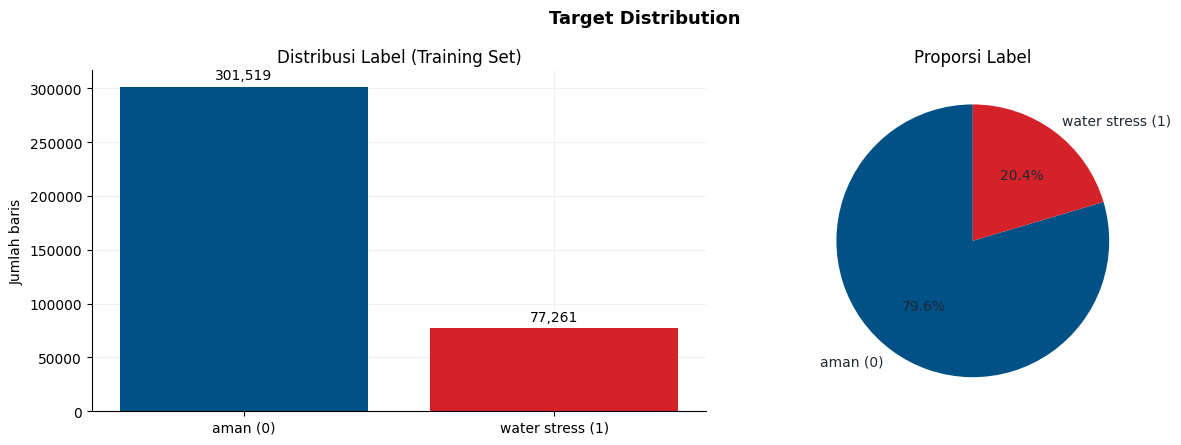

In [8]:
label_counts = train_raw.label.astype(int).value_counts().sort_index()
names = ['aman (0)', 'water stress (1)']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bars = ax1.bar(names, label_counts.values, color=[CFG.BLUE, CFG.RED])
ax1.bar_label(bars, labels=[f'{v:,}' for v in label_counts.values], padding=3)
ax1.set_ylabel('Jumlah baris')
ax1.set_title('Distribusi Label (Training Set)')
ax2.pie(label_counts.values, labels=names, colors=[CFG.BLUE, CFG.RED], autopct='%1.1f%%', startangle=90,
        textprops={'color': CFG.INK})
ax2.set_title('Proporsi Label')
fig.suptitle('Target Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '01_target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Kelas positif sekitar 20 persen, sehingga AP tebakan acak adalah 0.204. Ketidakseimbangan ini tidak ekstrem dan AP hanya bergantung pada urutan skor, sehingga *class weighting* atau *resampling* tidak diperlukan. Yang lebih penting adalah model mampu mengurutkan sub-DAS berisiko di atas sub-DAS aman.

---

## Format Angka

Setiap sel numerik diubah menjadi pola digit untuk melihat variasi format. Angka yang bersih seharusnya hanya berpola `9.9`.

9.9        98.318
9,9         0.726
9,9.9       0.235
-9          0.206
9           0.205
-9.9        0.181
9,9,9.9     0.114
9.9e-9      0.007

Contoh bulan non-numerik: ['April' 'december' 'Nov' 'Dec' 'june' 'april' 'September' 'December'
 'July' 'March' 'Aug' 'June']


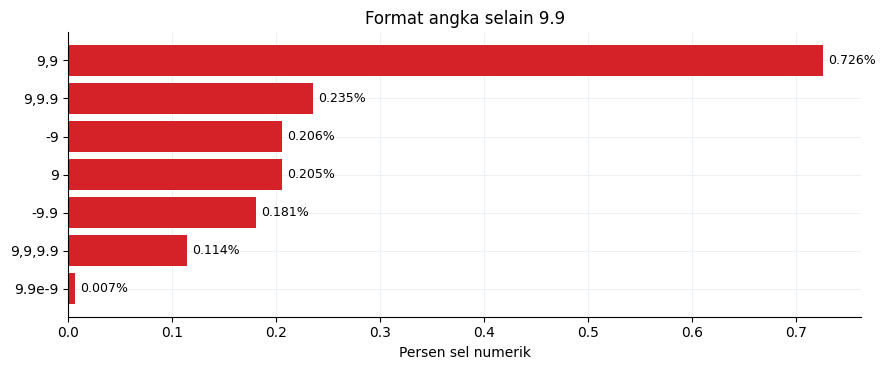

In [9]:
pattern = pd.concat([train_raw[c] for c in NUM_COLS]).dropna().str.replace(r'\d+', '9', regex=True)
share = (pattern.value_counts(normalize=True) * 100).head(8)
print(share.round(3).to_string())
print()
print('Contoh bulan non-numerik:', train_raw.loc[~train_raw.month.str.isdigit(), 'month'].unique()[:12])

fig, ax = plt.subplots(figsize=(9, 3.8))
other = share.drop('9.9')
ax.barh(other.index[::-1], other.values[::-1], color=CFG.RED)
for i, v in enumerate(other.values[::-1]):
    ax.text(v + 0.005, i, f'{v:.3f}%', va='center', fontsize=9)
ax.set_xlabel('Persen sel numerik')
ax.set_title('Format angka selain 9.9')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '02_number_formats.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Sekitar 1.7 persen sel memakai format lain: desimal koma (`1234,567`), pemisah ribuan (`1,234.567`), tanda negatif, dan notasi ilmiah. Pola `9,9` bersifat ambigu karena `890,694` dapat berarti 890.694 atau 890694. Ambiguitas ini diselesaikan di Prapemrosesan dengan uji kontinuitas antar lag.
>
> Kolom `month` juga tercampur antara angka, singkatan (`Feb`), nama lengkap (`February`), dan huruf kecil, sehingga memerlukan *parser* khusus.

---

## Kolom Auxiliary

Kamus data menyebut kolom `aux_*` sebagai noise, konstanta, salinan satuan, dan kode teks. Nilai tiap kolom dibandingkan antara *train* dan *test*.

In [10]:
aux_summary = pd.DataFrame({
    'train_nunique': train_raw[AUX].nunique(),
    'test_nunique': test_raw[AUX].nunique(),
    'train_example': train_raw[AUX].iloc[0],
    'test_example': test_raw[AUX].iloc[0],
})
aux_summary

,train_nunique,test_nunique,train_example,test_example
aux_noise_00,338383,11882,-0.263786,1.1075
aux_constant_01,1,1,0,-1
aux_twin_unit_02,54795,10271,7.05303,24.0869
aux_junk_id_03,378083,11928,ref-32803859,ref-50454249
aux_fake_mm_04,251773,11661,12323.4,12474.7
aux_noise_05,338649,11889,-1.46894,2.13177
aux_constant_06,1,1,0,-1
aux_twin_unit_07,297257,1242,2.13483,0
aux_junk_id_08,378065,11928,ref-03372354,ref-13257818
aux_fake_mm_09,251546,11699,12313.2,12482.7


> ### Insights
> Kolom `aux_constant_*` bernilai 0 di *train* tetapi -1 atau 999 di *test*, sehingga model yang memakainya akan melihat nilai yang tidak pernah muncul saat pelatihan. Kolom `aux_twin_unit_*` memetakan keluarga lag yang berbeda antara *train* dan *test*, dan bernilai 0 tepat pada sel sumber yang diformat dengan koma.
>
> Satu-satunya kolom *aux* yang berguna adalah `aux_fake_mm_*`, yaitu salinan `inc_aream2 / 10,000` dengan selisih sekitar 0.3 persen. Kolom ini dipakai untuk mengisi luas area yang hilang, lalu seluruh kolom *aux* dibuang.

---

## Struktur Target dan Split

Laju label, jumlah baris per *origin*, duplikasi pasangan (id, *origin*), serta irisan sub-DAS dan *origin* antara *train* dan *test* diperiksa bersama.

In [11]:
key = ['id', 'origin_id']
print('Label rate train      :', train_raw.label.astype(int).mean().round(4))
print('Origins train / test  :', train_raw.origin_id.nunique(), '/', test_raw.origin_id.nunique(),
      '| overlap:', len(set(train_raw.origin_id) & set(test_raw.origin_id)))
print('HUC train / test      :', train_raw.id.nunique(), '/', test_raw.id.nunique(),
      '| test HUC seen in train:', f'{test_raw.id.isin(train_raw.id).mean():.1%}')
dup = train_raw[train_raw.duplicated(key, keep=False)]
print('Duplicated (id, origin) rows:', len(dup), '| label conflicts:', (dup.groupby(key).label.nunique() > 1).sum())
print('Rows per test origin  :', test_raw.groupby('origin_id').size().to_dict())

Label rate train      : 0.204
Origins train / test  : 168 / 4 | overlap: 0
HUC train / test      : 2196 / 2982 | test HUC seen in train: 73.6%
Duplicated (id, origin) rows: 19580 | label conflicts: 0
Rows per test origin  : {'14': 2982, '169': 2982, '81': 2982, '94': 2982}


> ### Insights
> *Train* dan *test* tidak berbagi satu pun *origin*, dan 26 persen sub-DAS *test* tidak pernah muncul di *train*. Skema validasi karenanya harus menahan waktu dan sub-DAS sekaligus.
>
> Terdapat 9,728 pasangan (id, *origin*) yang muncul dua kali di *train* dengan label identik dan *jitter* kecil pada `clim_median_*`. Duplikat ini dibuang agar model tidak menghafal baris ganda dan agar baris yang sama tidak muncul di sisi *train* dan validasi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Prapemrosesan dilakukan bertahap dan setiap tahap diverifikasi: *parsing* -> dedup -> rekonstruksi timeline -> perbaikan korupsi -> koreksi skala klimatologi. Kunci verifikasinya adalah struktur lag: nilai bulan yang sama muncul pada hingga 12 baris dari *origin* berurutan, sehingga median lintas baris menjadi *ground truth* untuk menilai apakah perbaikan benar-benar mengembalikan nilai asli.

## Parsing Angka dan Bulan

Aturan *parsing*: jika sel memuat koma dan titik, koma adalah pemisah ribuan. Jika hanya memuat koma, koma adalah desimal. Aturan kedua diuji pada sel ambigu `ddd,ddd` dengan membandingkan rasio lag1 terhadap lag2 yang bersebelahan dalam waktu. `to_id` dinormalisasi (spasi dan huruf besar) agar jaringan sungai tidak terputus.

In [12]:
MONTHS = {m: i + 1 for i, m in enumerate(
    ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])}

def parse_num(s):
    s = s.astype('string').str.strip()
    both = s.str.contains(',', regex=False) & s.str.contains('.', regex=False)
    s = s.mask(both, s.str.replace(',', '', regex=False))
    s = s.str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce').astype('float64')

def parse_month(s):
    s = s.astype('string').str.strip().str.lower()
    return pd.to_numeric(s, errors='coerce').fillna(s.str[:3].map(MONTHS)).astype('int64')

def parse_frame(df):
    out = df[['row_id', 'id', 'to_id']].copy()
    out['to_id'] = df.to_id.str.strip().str.lower()
    out['row_id'] = out.row_id.astype(int)
    out['origin_id'] = df.origin_id.astype(int)
    out['month'] = parse_month(df.month)
    for c in NUM_COLS:
        out[c] = parse_num(df[c])
    for c in ['aux_fake_mm_04', 'aux_fake_mm_09', 'aux_fake_mm_14']:
        out[c] = pd.to_numeric(df[c], errors='coerce')
    if 'label' in df:
        out['label'] = df.label.astype(int)
    return out

train = parse_frame(train_raw)
test = parse_frame(test_raw)
for name, raw_df, df in [('train', train_raw, train), ('test', test_raw, test)]:
    print(f'{name}: to_id distinct raw {raw_df.to_id.nunique()} -> normalised {df.to_id.nunique()}, '
          f'max to_id per id raw {raw_df.groupby("id").to_id.nunique().max()} -> {df.groupby("id").to_id.nunique().max()}')

for fam in ['q_bf_inc_m3', 'q_qf_inc_m3', 'q_ws_cum_m3', 'q_ps_wd_inc_m3']:
    a, b = train[f'{fam}_lag1'], train[f'{fam}_lag2']
    amb = train_raw[f'{fam}_lag1'].str.fullmatch(r'\d{1,3},\d{3}').fillna(False) & (a > 1) & (b > 1)
    dec = np.log10(a[amb] / b[amb]).abs().median()
    thou = np.log10(a[amb] * 1000 / b[amb]).abs().median()
    print(f'{fam:16s} ambiguous n={amb.sum():4d}  |log10(lag1/lag2)| decimal-comma {dec:.2f} vs thousands {thou:.2f}')

train: to_id distinct raw 2976 -> normalised 1097, max to_id per id raw 4 -> 1
test: to_id distinct raw 1625 -> normalised 1497, max to_id per id raw 2 -> 1
q_bf_inc_m3      ambiguous n= 316  |log10(lag1/lag2)| decimal-comma 0.04 vs thousands 2.98
q_qf_inc_m3      ambiguous n= 487  |log10(lag1/lag2)| decimal-comma 0.64 vs thousands 2.61
q_ws_cum_m3      ambiguous n= 138  |log10(lag1/lag2)| decimal-comma 0.19 vs thousands 2.93
q_ps_wd_inc_m3   ambiguous n= 120  |log10(lag1/lag2)| decimal-comma 0.02 vs thousands 3.00


> ### Insights
> Interpretasi desimal koma memberi rasio lag1/lag2 hampir 1 (log 0.02 sampai 0.64), sedangkan interpretasi pemisah ribuan meleset sekitar 1000 kali (log sekitar 3). Aturan *parsing* terbukti benar.
>
> `to_id` juga terkorupsi dengan spasi dan huruf besar. Di *train*, 2,976 nilai mentah hanya mewakili 1,097 ID, dan satu sub-DAS bisa memiliki sampai 4 varian `to_id`. Setelah normalisasi, setiap sub-DAS memiliki tepat satu `to_id`.

---

## Penanganan Duplikat

Duplikat pasangan (id, *origin*) dibuang dengan mempertahankan kemunculan pertama. Karena label dan seluruh lag pada pasangan duplikat identik, pembuangan ini tidak menghilangkan informasi, tetapi mencegah baris yang sama dihitung dua kali dan mencegah satu baris muncul di sisi *train* dan validasi sekaligus.

Train rows 378780 -> 368928 (dropped 9852, 2.60%)


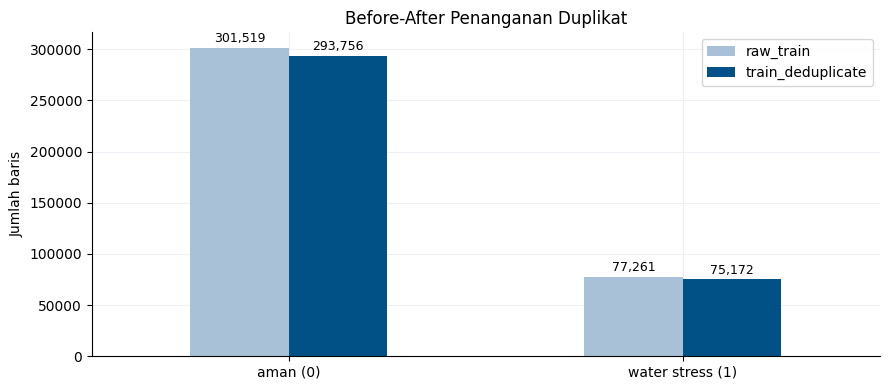

In [13]:
before = train.label.value_counts().sort_index()
n0 = len(train)
train = train.drop_duplicates(['id', 'origin_id']).reset_index(drop=True)
after = train.label.value_counts().sort_index()
print(f'Train rows {n0} -> {len(train)} (dropped {n0 - len(train)}, {100 * (n0 - len(train)) / n0:.2f}%)')

plot_df = pd.DataFrame({'raw_train': before.values, 'train_deduplicate': after.values}, index=['aman (0)', 'water stress (1)'])
fig, ax = plt.subplots(figsize=(9, 4))
plot_df.plot(kind='bar', ax=ax, color=[CFG.LIGHT, CFG.BLUE])
for cont in ax.containers:
    ax.bar_label(cont, labels=[f'{v:,.0f}' for v in cont.datavalues], padding=2, fontsize=9)
ax.set_title('Before-After Penanganan Duplikat')
ax.set_ylabel('Jumlah baris')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '03_dedup.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Sebanyak 9,852 baris (2.6 persen) dibuang dan proporsi label tidak berubah. Kebocoran yang jauh lebih besar justru datang dari waktu: satu nilai bulanan muncul di sampai 12 baris lewat kolom lag. Kebocoran ini ditangani di skema validasi (blok waktu dengan *purge* 12 bulan), bukan dengan dedup.

---

## Rekonstruksi Timeline

`origin_id` adalah ID acak, tetapi urutan waktunya dapat dipulihkan. Untuk sub-DAS yang sama, nilai lag0 pada *origin* t muncul lagi sebagai lag1 pada *origin* t+1. Pasangan *origin* dihitung votingnya dari seluruh sub-DAS, lalu dirangkai menjadi rantai.

In [14]:
def lag_keys(df, lag):
    k = pd.DataFrame({'id': df.id, 'v': df[f'q_bf_inc_m3_lag{lag}'].round(1), 'origin_id': df.origin_id})
    return k[k.v > 0].drop_duplicates(['id', 'v', 'origin_id'])

def recover_timeline(df, max_gap=11, min_votes=200):
    cur = lag_keys(df, 0).rename(columns={'origin_id': 'earlier'})
    parts = []
    for k in range(1, max_gap + 1):
        m = cur.merge(lag_keys(df, k).rename(columns={'origin_id': 'later'}), on=['id', 'v'])
        m = m[m.earlier != m.later]
        parts.append(m.groupby(['earlier', 'later']).size().rename('n').reset_index().assign(gap=k))
    edges = pd.concat(parts)
    edges = edges[edges.n >= min_votes]
    nxt = (edges[edges.gap == 1].sort_values('n', ascending=False)
           .drop_duplicates('earlier').drop_duplicates('later').set_index('earlier').later)
    starts = sorted(set(nxt.index) - set(nxt.values))
    chains = []
    for s in starts:
        c = [s]
        while c[-1] in nxt.index:
            c.append(int(nxt[c[-1]]))
        chains.append(c)
    return sorted(chains, key=len, reverse=True), edges

both_parsed = pd.concat([train, test], ignore_index=True)
chains, edges = recover_timeline(both_parsed)
chain = chains[0]
t_of = {o: i for i, o in enumerate(chain)}
train['t'] = train.origin_id.map(t_of)
month_of = train.groupby('origin_id').month.first()
ok = np.mean([(month_of[b] - month_of[a]) % 12 == 1 for a, b in zip(chain[:-1], chain[1:])])
print(f'Chains found: {[len(c) for c in chains]}, month+1 consistency {ok:.1%}')
test_links = edges[edges.earlier.isin(test.origin_id) | edges.later.isin(test.origin_id)]
print('Links between test origins and any other origin (gap 1..11):', len(test_links))

Chains found: [168], month+1 consistency 100.0%
Links between test origins and any other origin (gap 1..11): 0


> ### Insights
> Seluruh 168 *origin train* membentuk satu rantai 168 bulan berturut-turut dengan konsistensi bulan 100 persen. Keempat *origin test* tidak terhubung ke *origin* mana pun dalam jarak 1 sampai 11 bulan, sehingga *test* adalah blok waktu terpisah tanpa kebocoran lag. Validasi yang jujur harus menahan blok waktu utuh dengan jarak aman 12 bulan.

---

## Penjangkaran Kalender

Rantai hanya memberi urutan relatif. Untuk mengetahui posisi *test* terhadap *train*, dicari kolom yang berubah pada tanggal absolut yang diketahui. Pengambilan air *thermoelectric* bernilai nol di seluruh sub-DAS sampai satu bulan tertentu lalu menyala serentak, dan data reanalisis *thermoelectric* USGS memang dimulai Januari 2008.

origin_id 0..251: 252 ids = 21 years; train 168, test 4, never shown 80
thermoelectric switches on at chain month 88 -> chain month 0 = 2000-09, train = 2000-09 .. 2014-08
test: smallest thermoelectric nonzero share over the 12 lags 0.0060 -> every test window is after 2008-01; test origins lie in 2015-08 .. 2020-08


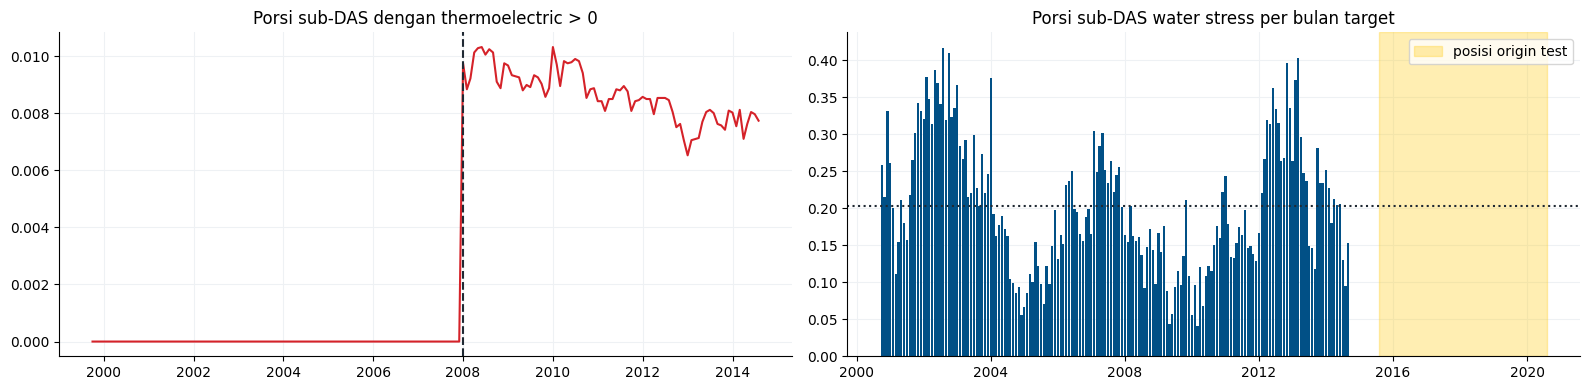

Driest target months: {'2002-08': 0.417, '2002-10': 0.41, '2013-03': 0.403, '2012-11': 0.397, '2002-05': 0.388}


In [15]:
th = pd.concat([pd.DataFrame({'m': train.t - k,
                              'nz': train[f'q_th_wd_inc_m3_lag{k}'].abs().gt(0) & train[f'q_th_wd_inc_m3_lag{k}'].ne(-9999)})
                for k in LAGS]).groupby('m').nz.mean()
switch = int(th.index[th > 0.002].min())
T0 = pd.Timestamp('2008-01-01') - pd.DateOffset(months=switch)
date_of = lambda k: (T0 + pd.DateOffset(months=int(k))).strftime('%Y-%m')
n_ids = max(train.origin_id.max(), test.origin_id.max()) + 1
print(f'origin_id 0..{n_ids - 1}: {n_ids} ids = {n_ids / 12:.0f} years; train {train.origin_id.nunique()}, '
      f'test {test.origin_id.nunique()}, never shown {n_ids - train.origin_id.nunique() - test.origin_id.nunique()}')
print(f'thermoelectric switches on at chain month {switch} -> chain month 0 = {date_of(0)}, '
      f'train = {date_of(0)} .. {date_of(train.t.max())}')
te_th = min(((test[f'q_th_wd_inc_m3_lag{k}'].abs() > 0) & (test[f'q_th_wd_inc_m3_lag{k}'] != -9999)).mean() for k in LAGS)
print(f'test: smallest thermoelectric nonzero share over the 12 lags {te_th:.4f} -> every test window is after '
      f'{date_of(switch)}; test origins lie in {date_of(train.t.max() + 12)} .. 2020-08')

prev_t = train.groupby('t').label.mean()
dates = [T0 + pd.DateOffset(months=int(k) + 1) for k in prev_t.index]
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot([T0 + pd.DateOffset(months=int(k)) for k in th.index], th.values, color=CFG.RED)
ax[0].axvline(pd.Timestamp('2008-01-01'), ls='--', c=CFG.INK)
ax[0].set_title('Porsi sub-DAS dengan thermoelectric > 0')
ax[1].bar(dates, prev_t.values, width=25, color=CFG.BLUE)
ax[1].axvspan(T0 + pd.DateOffset(months=int(train.t.max()) + 12), pd.Timestamp('2020-08-01'), color=CFG.YELLOW, alpha=.35,
              label='posisi origin test')
ax[1].axhline(train.label.mean(), ls=':', c=CFG.INK)
ax[1].legend(loc='upper right')
ax[1].set_title('Porsi sub-DAS water stress per bulan target')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '04_calendar_anchor.png', dpi=120, bbox_inches='tight')
plt.show()
top = prev_t.sort_values(ascending=False).head(5)
print('Driest target months:', {date_of(k + 1): round(v, 3) for k, v in top.items()})

> ### Insights
> `origin_id` berjalan dari 0 sampai 251, yaitu 252 bulan atau 21 *water year* (Oktober 1999 sampai September 2020). *Thermoelectric* menyala tepat pada bulan rantai ke-88 yang jatuh di bulan Januari, sehingga bulan rantai ke-0 adalah September 2000 dan *train* mencakup September 2000 sampai Agustus 2014.
>
> Pemeriksaan silang tanpa data eksternal: bulan paling kering di *train* jatuh pada 2002 dan akhir 2012 sampai awal 2013, dua kekeringan besar di Amerika Serikat. Seluruh lag *test* memuat *thermoelectric* dan tidak ada yang tumpang tindih dengan rantai, sehingga keempat *origin test* berada di masa depan (Agustus 2015 sampai Agustus 2020). Konsekuensinya, validasi juga diuji dengan skema maju dan dicek apakah ada *concept drift* (bagian Evaluasi).

---

## Perbaikan Korupsi

Korupsi yang ditemukan: *sentinel* `-9999`, tanda negatif yang terbalik, sel NaN, nol yang disisipkan pada seri yang mulus, dan *spike* dengan pengali 10 sampai 100 kali. Perbaikan tahap pertama bekerja per baris: nol sisipan dideteksi lebih dulu, lalu *spike*, lalu nilai yang hilang diisi dengan identitas *water budget* `ws = bf + qf + inflow hulu` dengan *inflow* diinterpolasi sepanjang lag. Aturan *spike* tidak dipakai pada *thermoelectric* karena pembangkit memang bisa menyala dan mati, dan *spike* pada `ws` dipertahankan jika neraca `bf + qf + inflow` mendukungnya (bulan badai asli).

Tahap kedua memakai jaringan sungai: *inflow* hulu sebuah sub-DAS sama dengan jumlah `ws` sub-DAS hulunya pada *origin* yang sama. Karena *test* mengalikan setiap sub-DAS dengan faktor acak sendiri, identitas ditulis sebagai `ws(h) = bf(h) + qf(h) + sum c_u ws(u)` dengan `c_u = f_h / f_u`. Koefisien `c` diestimasi dengan NNLS per sub-DAS hilir dari sel yang bersih, dan hanya dipakai jika galat median di bawah 1 persen.

In [16]:
SENTINELS = [-9999.0, -9.999]
SPIKE_FAMS = {'q_bf_inc_m3': 8.0, 'q_ws_cum_m3': 12.0, 'q_ps_wd_inc_m3': 5.0}
ZERO_FAMS = ['q_bf_inc_m3', 'q_ps_wd_inc_m3', 'q_ws_cum_m3']

def lag_block(df, fam):
    return df[[f'{fam}_lag{k}' for k in LAGS]].to_numpy(dtype='float64', copy=True)

def interp_log(x):
    lx = pd.DataFrame(np.log1p(x)).T.interpolate(limit_direction='both').T.to_numpy()
    return np.where(np.isnan(x), np.expm1(lx), x)

def neighbour(x, fn):
    p = np.pad(x, ((0, 0), (1, 1)), constant_values=np.nan)
    return fn(p[:, :-2], p[:, 2:])

def flag_corruption(x, fam, spike=True, zero=True, zero_first=True):
    x[np.isin(x, SENTINELS)] = np.nan
    x = np.abs(x)
    if zero_first and zero and fam in ZERO_FAMS:
        x[(x == 0) & (neighbour(x, np.fmin) > 10)] = np.nan
    if spike and fam in SPIKE_FAMS:
        nb = neighbour(np.where(x == 0, np.nan, x) if zero_first else x, np.fmax)
        x[x > SPIKE_FAMS[fam] * nb] = np.nan
    if not zero_first and zero and fam in ZERO_FAMS:
        x[(x == 0) & (neighbour(x, np.fmin) > 10)] = np.nan
    return x

def raw_abs(df, fam):
    x = lag_block(df, fam)
    return np.abs(np.where(np.isin(x, SENTINELS), np.nan, x))

def flag_blocks(df, spike=True, zero=True, zero_first=True, storm=True):
    B = {f: flag_corruption(lag_block(df, f), f, spike, zero, zero_first) for f in FLOWS}
    if storm and spike:
        x, bf, qf = raw_abs(df, 'q_ws_cum_m3'), raw_abs(df, 'q_bf_inc_m3'), raw_abs(df, 'q_qf_inc_m3')
        inflow_nb = np.nan_to_num(neighbour(np.clip(x - bf - qf, 0, None), np.fmax))
        backed = (x > 0) & (x <= 1.5 * (bf + qf + inflow_nb))
        B['q_ws_cum_m3'] = np.where(np.isnan(B['q_ws_cum_m3']) & backed, x, B['q_ws_cum_m3'])
    return B

def repair(df, spike=True, zero=True, identity=True, zero_first=True, storm=True):
    B = flag_blocks(df, spike, zero, zero_first, storm)
    if identity:
        bf, qf, ws = interp_log(B['q_bf_inc_m3']), B['q_qf_inc_m3'], B['q_ws_cum_m3']
        inflow = interp_log(np.clip(ws - bf - qf, 0, None))
        ws = np.where(np.isnan(ws), bf + np.nan_to_num(qf) + inflow, ws)
        qf = np.where(np.isnan(qf), np.clip(ws - bf - inflow, 0, None), qf)
        B['q_bf_inc_m3'], B['q_qf_inc_m3'], B['q_ws_cum_m3'] = bf, qf, ws
    out = df.copy()
    for f, x in B.items():
        out[[f'{f}_lag{k}' for k in LAGS]] = interp_log(x)
    return out

BUDGET = ('q_ws_cum_m3', 'q_bf_inc_m3', 'q_qf_inc_m3')

def network_fill(df, X, tol=0.01, min_cells=6):
    B = flag_blocks(df)
    flag = {f: np.isnan(B[f]) for f in BUDGET}
    ws, bf, qf = (X[[f'{f}_lag{k}' for k in LAGS]].to_numpy(dtype='float64', copy=True) for f in BUDGET)
    pos = pd.Series(np.arange(len(df)), pd.MultiIndex.from_arrays([df.id.values, df.origin_id.values]))
    pos = pos[~pos.index.duplicated()]
    down = pos.reindex(pd.MultiIndex.from_arrays([df.to_id.values, df.origin_id.values])).to_numpy()
    e = pd.DataFrame({'d': down, 'u': np.arange(len(df)), 'h': df.to_id.values, 'uh': df.id.values}).dropna()
    e['d'] = e.d.astype(int)
    anyflag = flag['q_ws_cum_m3'] | flag['q_bf_inc_m3'] | flag['q_qf_inc_m3']
    new_ws, new_bf, new_qf = ws.copy(), bf.copy(), qf.copy()
    used = 0
    for _, g in e.groupby('h', sort=False):
        ups = {u: i for i, u in enumerate(pd.unique(g.uh))}
        rows = np.unique(g.d.values)
        ri = {r: i for i, r in enumerate(rows)}
        S = np.zeros((len(rows), 12, len(ups)))
        S_bad = np.zeros((len(rows), 12), bool)
        for d, u, uh in zip(g.d.values, g.u.values, g.uh.values):
            S[ri[d], :, ups[uh]] = ws[u]
            S_bad[ri[d]] |= flag['q_ws_cum_m3'][u]
        clean = ~anyflag[rows] & ~S_bad & np.isfinite(S).all(-1)
        if clean.sum() < min_cells:
            continue
        inflow = np.clip(ws[rows] - bf[rows] - qf[rows], 0, None)
        c, _ = nnls(S[clean], inflow[clean])
        up = np.nan_to_num(S @ c)
        pred = bf[rows] + qf[rows] + up
        if np.median(np.abs(pred[clean] - ws[rows][clean]) / np.maximum(ws[rows][clean], 1e-9)) > tol:
            continue
        used += 1
        fw, fb, fq = flag['q_ws_cum_m3'][rows], flag['q_bf_inc_m3'][rows], flag['q_qf_inc_m3'][rows]
        new_ws[rows] = np.where(fw & ~fb & ~fq, pred, new_ws[rows])
        new_qf[rows] = np.where(fq & ~fw & ~fb, np.clip(ws[rows] - bf[rows] - up, 0, None), new_qf[rows])
        new_bf[rows] = np.where(fb & ~fw & ~fq, np.clip(ws[rows] - qf[rows] - up, 0, None), new_bf[rows])
    out = X.copy()
    for f, v in zip(BUDGET, (new_ws, new_bf, new_qf)):
        out[[f'{f}_lag{k}' for k in LAGS]] = v
    out.attrs['network_hucs'] = used
    return out

def full_repair(df):
    return network_fill(df, repair(df))

---

## Verifikasi Perbaikan

Setiap konfigurasi perbaikan dinilai terhadap *ground truth* lintas baris. Metrik utama adalah persentase sel korup yang kembali ke dalam 25 persen dari nilai asli, dan persentase sel bersih yang ikut rusak. Konfigurasi `a` sampai `g` menambahkan satu langkah perbaikan setiap kali, sehingga kontribusi setiap langkah terlihat.

In [17]:
def ground_truth(df, fam):
    long = pd.concat([pd.DataFrame({'id': df.id, 'm': df.t - k, 'v': df[f'{fam}_lag{k}']}) for k in LAGS])
    gt = long.groupby(['id', 'm']).v.median()
    return np.column_stack([gt.reindex(pd.MultiIndex.from_arrays([df.id, df.t - k])).to_numpy() for k in LAGS])

def rel_err(X, G):
    with np.errstate(divide='ignore', invalid='ignore'):
        e = np.abs(X - G) / np.abs(G)
    return np.where(np.isnan(X), np.inf, e)

GT = {f: ground_truth(train, f) for f in FLOWS}
configs = {
    'a interp only': lambda d: repair(d, spike=False, zero=False, identity=False, storm=False),
    'b +spike': lambda d: repair(d, zero=False, identity=False, zero_first=False, storm=False),
    'c +zero': lambda d: repair(d, identity=False, zero_first=False, storm=False),
    'd +budget identity': lambda d: repair(d, zero_first=False, storm=False),
    'e zero before spike': lambda d: repair(d, storm=False),
    'f +storm check': lambda d: repair(d),
    'g +network budget': full_repair,
}
rows = []
for name, fn in configs.items():
    fixed = fn(train)
    for fam in FLOWS:
        cols = [f'{fam}_lag{k}' for k in LAGS]
        G, raw, X = GT[fam], train[cols].to_numpy(), fixed[cols].to_numpy()
        ok = ~np.isnan(G) & (np.abs(G) > 0)
        bad = ok & ~(rel_err(raw, G) < 1e-3)
        e = rel_err(X, G)
        rows.append({'config': name, 'family': fam, 'corrupt_%': 100 * bad.mean(),
                     'fixed_within_25%': 100 * (e[bad] < 0.25).mean(),
                     'clean_damaged_%': 100 * (e[ok & ~bad] > 0.05).mean()})
verify = pd.DataFrame(rows)
display(verify.pivot(index='family', columns='config', values='fixed_within_25%').round(1))
display(verify.pivot(index='family', columns='config', values='clean_damaged_%').round(3))

config,a interp only,b +spike,c +zero,d +budget identity,e zero before spike,f +storm check,g +network budget
family,,,,,,,
q_bf_inc_m3,64.1,68.9,74.4,74.4,74.9,74.9,78.4
q_ir_wd_inc_m3,26.6,26.6,26.6,26.6,26.6,26.6,26.6
q_ps_wd_inc_m3,83.2,89.8,97.8,97.8,98.2,98.2,98.2
q_qf_inc_m3,19.3,19.3,19.3,46.1,46.1,46.1,61.6
q_th_wd_inc_m3,53.2,53.2,53.2,53.2,53.2,53.2,53.2
q_ws_cum_m3,48.5,51.9,56.1,80.7,80.9,80.9,91.3


config,a interp only,b +spike,c +zero,d +budget identity,e zero before spike,f +storm check,g +network budget
family,,,,,,,
q_bf_inc_m3,0.000,0.135,0.131,0.131,0.091,0.091,0.079
q_ir_wd_inc_m3,0.002,0.002,0.002,0.002,0.002,0.002,0.002
q_ps_wd_inc_m3,0.001,0.045,0.032,0.032,0.001,0.001,0.001
q_qf_inc_m3,0.001,0.001,0.001,0.001,0.001,0.001,0.001
q_th_wd_inc_m3,0.041,0.041,0.041,0.041,0.041,0.041,0.041
q_ws_cum_m3,0.000,0.397,0.395,0.127,0.106,0.087,0.056


Distribusi sel `ws` yang korup ditampilkan sebelum perbaikan, sesudah perbaikan, dan pada *ground truth* untuk memeriksa secara visual bahwa hasil perbaikan kembali ke sebaran nilai asli.

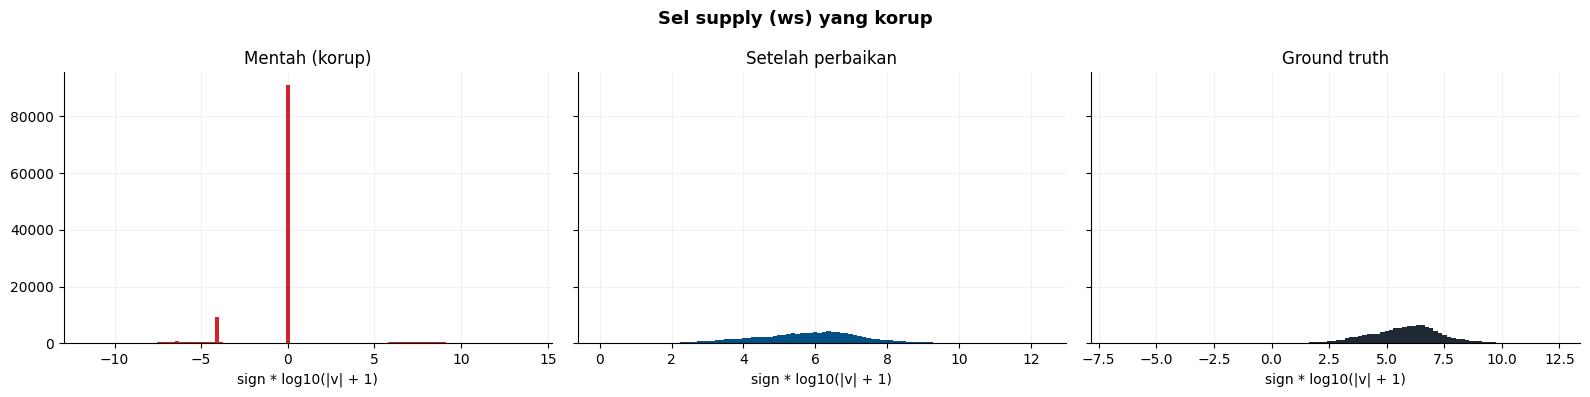

In [18]:
fam = 'q_ws_cum_m3'
cols = [f'{fam}_lag{k}' for k in LAGS]
G, raw = GT[fam], train[cols].to_numpy()
bad = ~np.isnan(G) & (np.abs(G) > 0) & ~(rel_err(raw, G) < 1e-3)
fixed = full_repair(train)[cols].to_numpy()

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, (title, x, col) in zip(ax, [('Mentah (korup)', raw[bad], CFG.RED), ('Setelah perbaikan', fixed[bad], CFG.BLUE),
                                   ('Ground truth', G[bad], CFG.INK)]):
    v = np.nan_to_num(x, nan=0)
    a.hist(np.sign(v) * np.log10(np.abs(v) + 1), bins=100, color=col)
    a.set_title(title)
    a.set_xlabel('sign * log10(|v| + 1)')
fig.suptitle('Sel supply (ws) yang korup', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '05_repair_check.png', dpi=120, bbox_inches='tight')
plt.show()

Sebagian sel bersih ikut rusak. Sel bersih yang salah ditandai korup dihitung per lag untuk tiga versi aturan: urutan lama (*spike* lalu nol), nol lebih dulu, dan nol lebih dulu ditambah pengecekan neraca untuk bulan badai.

In [19]:
fam = 'q_ws_cum_m3'
cols = [f'{fam}_lag{k}' for k in LAGS]
G, raw = GT[fam], train[cols].to_numpy()
clean = ~np.isnan(G) & (np.abs(G) > 0) & (rel_err(raw, G) < 1e-3)
spike_true = ~np.isnan(G) & (np.abs(G) > 0) & (raw / G >= 5) & (raw / G <= 200)
rows = []
for name, kw in [('spike before zero', dict(zero_first=False, storm=False)),
                 ('zero before spike', dict(storm=False)), ('+ storm check', {})]:
    flagged = np.isnan(flag_blocks(train, **kw)[fam])
    wrong = flagged & clean
    rows.append({'rule': name, **{f'lag{k}': int(wrong[:, k].sum()) for k in LAGS},
                 'clean flagged': int(wrong.sum()), 'injected spikes caught': f'{flagged[spike_true].mean():.4f}'})
display(pd.DataFrame(rows).set_index('rule'))

,lag0,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,lag9,lag10,lag11,clean flagged,injected spikes caught
rule,,,,,,,,,,,,,,
spike before zero,5679,836,872,823,843,849,865,852,881,835,812,2889,17036,0.8690
zero before spike,4868,802,828,795,804,818,823,814,823,809,782,2082,15048,0.8683
+ storm check,1526,198,198,176,196,188,193,186,210,186,189,464,3910,0.8677


> ### Insights
> Interpolasi saja hanya mengembalikan sekitar setengah sel `ws` korup ke dalam 25 persen dari nilai asli. Deteksi *spike* dan nol menaikkannya sedikit, dan identitas *water budget* menaikkannya ke sekitar 80 persen. *Quickflow* naik dari 19 ke 46 persen, dan sel dengan tanda terbalik pulih 100 persen.
>
> Pemeriksaan per contoh menemukan dua cacat pada aturan awal. Pertama, *spike* diperiksa sebelum nol, sehingga nilai bersih yang tetangganya nol sisipan terlihat seperti *spike* lalu ditimpa. Kedua, di ujung jendela (lag0 dan lag11) hanya ada satu tetangga, sehingga bulan badai asli ikut ditandai *spike*: sekitar 4,900 sel bersih di lag0 saja. Pengecekan neraca `ws <= 1.5 (bf + qf + inflow)` mengembalikan 74 persen *false flag* dan hanya melewatkan 5 dari 7,033 *spike* sisipan.
>
> Neraca air jaringan sungai menaikkan sel `ws` korup yang pulih dalam 5 persen dari nilai asli dari 0.613 ke 0.840, dan sel `ws` bersih yang ikut rusak turun dari 0.127 ke 0.055 persen. Iterasi awal sempat merusak data: aturan *spike* pada *thermoelectric* merusak 1.8 persen sel bersih, dan identitas untuk *baseflow* menurunkan akurasinya dari 74 ke 61 persen, sehingga keduanya diganti.

---

## Koreksi Skala Klimatologi

Rasio `ws_lag0 / clim_median_now` membandingkan bulan kalender yang sama, sehingga seharusnya berada di sekitar 1. Median log-rasio per sub-DAS menunjukkan kelompok yang bergeser tepat 1000 kali.

HUC clim exponent counts: {0.0: 2788, -3.0: 106, 3.0: 84, inf: 4}


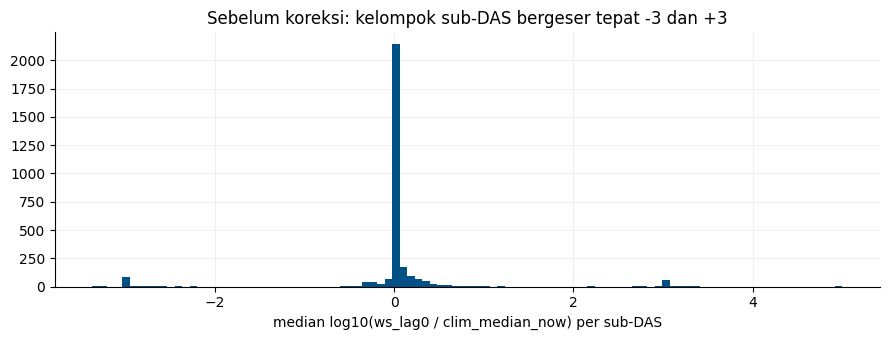

In [20]:
def clim_scale(df):
    a = np.log10((df.q_ws_cum_m3_lag0.abs() / df.clim_median_now).where(lambda s: s > 0))
    b = np.log10((df.q_ws_cum_m3_lag11.abs() / df.clim_median_next).where(lambda s: s > 0))
    h = pd.concat([a, b]).groupby(pd.concat([df.id, df.id])).median()
    return (3 * np.round(df.id.map(h) / 3)).fillna(0)

both_parsed = pd.concat([train, test], ignore_index=True)
scale = clim_scale(both_parsed)
per_huc = scale.groupby(both_parsed.id).first()
print('HUC clim exponent counts:', per_huc.value_counts().to_dict())
raw_ratio = np.log10((both_parsed.q_ws_cum_m3_lag0.abs() / both_parsed.clim_median_now).where(lambda s: s > 0))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(raw_ratio.groupby(both_parsed.id).median().clip(-5, 5), bins=100, color=CFG.BLUE)
ax.set_xlabel('median log10(ws_lag0 / clim_median_now) per sub-DAS')
ax.set_title('Sebelum koreksi: kelompok sub-DAS bergeser tepat -3 dan +3')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '06_clim_scale.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Sekitar 6 persen sub-DAS memiliki klimatologi yang bergeser tepat 10^3 atau 10^-3 kali. Tanpa koreksi, rasio pasokan terhadap klimatologi pada sub-DAS ini tidak bermakna: baris dengan rasio di atas 5 masih memiliki label positif 7.5 persen, sesuatu yang mustahil menurut definisi label. Setelah koreksi eksponen kelipatan 3, anomali tersebut hilang.

---

## Konsistensi Train-Test

Kolom statis dan klimatologi sebuah sub-DAS tidak bergantung waktu, sehingga untuk sub-DAS yang muncul di *train* dan *test* nilainya harus sama. Pemeriksaan ini dilakukan setelah versi pertama mendapat *public score* 0.423, jauh di bawah CV 0.703.

Static columns equal for seen HUCs: {'inc_aream2': np.float64(1.0), 'cum_aream2': np.float64(1.0), 'pop_dec_2000': np.float64(1.0), 'pop_dec_2010': np.float64(0.999), 'pop_dec_2020': np.float64(0.999), 'pop_acs_2020': np.float64(1.0)}
Same (HUC, month) climatology equal in train and test: 0.012
Within-HUC std of log10(test/train clim): median 0.0000
Per-HUC factor quantiles p5/p50/p95: [0.252, 0.993, 4.062]
q_ws_cum_m3     IQR log10(test/train median): raw 0.746 -> divided by HUC factor 0.471
q_bf_inc_m3     IQR log10(test/train median): raw 0.717 -> divided by HUC factor 0.397
q_ps_wd_inc_m3  IQR log10(test/train median): raw 0.644 -> divided by HUC factor 0.087


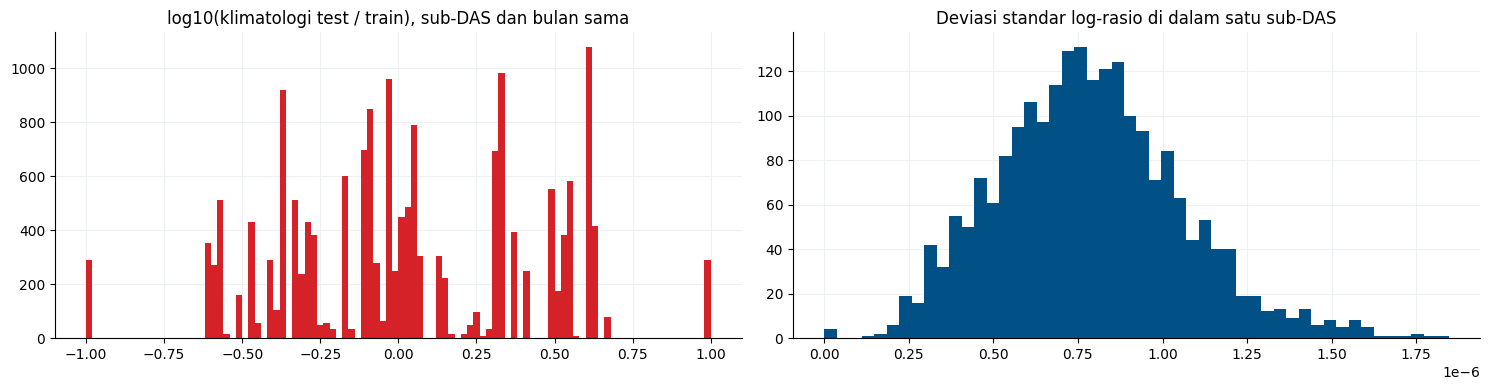

In [21]:
seen_ids = sorted(set(train.id) & set(test.id))
st_equal = {c: np.isclose(test.groupby('id')[c].median().loc[seen_ids],
                          train.groupby('id')[c].median().loc[seen_ids], rtol=1e-3).mean() for c in STATIC}
print('Static columns equal for seen HUCs:', {k: round(v, 3) for k, v in st_equal.items()})

def clim_long(df):
    e = 10.0 ** clim_scale(df)
    return pd.concat([pd.DataFrame({'id': df.id, 'm': df.month, 'c': df.clim_median_now * e}),
                      pd.DataFrame({'id': df.id, 'm': df.month % 12 + 1, 'c': df.clim_median_next * e})])

ct = clim_long(train).groupby(['id', 'm']).c.median()
ce = clim_long(test).groupby(['id', 'm']).c.median()
pair = pd.concat([ct.rename('train'), ce.rename('test')], axis=1).dropna()
pair['log_ratio'] = np.log10(pair.test / pair.train)
per_huc = pair.groupby(level=0).log_ratio.agg(['mean', 'std'])
print(f'Same (HUC, month) climatology equal in train and test: {(pair.log_ratio.abs() < .01).mean():.3f}')
print(f'Within-HUC std of log10(test/train clim): median {per_huc["std"].median():.4f}')
factor = 10 ** per_huc['mean']
print(f'Per-HUC factor quantiles p5/p50/p95: {factor.quantile([.05, .5, .95]).round(3).tolist()}')

T = test[test.id.isin(seen_ids)]
for fam in ['q_ws_cum_m3', 'q_bf_inc_m3', 'q_ps_wd_inc_m3']:
    ref = pd.DataFrame({'id': train.id, 'm': train.month, 'v': train[f'{fam}_lag0'].abs()}).groupby(['id', 'm']).v.median()
    base = ref.reindex(pd.MultiIndex.from_arrays([T.id, T.month])).values
    raw = np.log10(T[f'{fam}_lag0'].abs() / base).replace([np.inf, -np.inf], np.nan)
    unf = np.log10(T[f'{fam}_lag0'].abs() / T.id.map(factor) / base).replace([np.inf, -np.inf], np.nan)
    iqr = lambda s: s.quantile(.75) - s.quantile(.25)
    print(f'{fam:15s} IQR log10(test/train median): raw {iqr(raw):.3f} -> divided by HUC factor {iqr(unf):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].hist(pair.log_ratio.clip(-1, 1), bins=100, color=CFG.RED)
ax[0].set_title('log10(klimatologi test / train), sub-DAS dan bulan sama')
ax[1].hist(per_huc['std'].clip(0, .05), bins=50, color=CFG.BLUE)
ax[1].set_title('Deviasi standar log-rasio di dalam satu sub-DAS')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '07_test_rescale.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Kolom statis identik, jadi ID sub-DAS konsisten antara *train* dan *test*. Namun klimatologi sub-DAS dan bulan yang sama hanya cocok sekitar 1 persen, dan log-rasionya konstan di dalam setiap sub-DAS (deviasi standar 0). Artinya setiap sub-DAS di *test* dikalikan satu faktor acak antara sekitar 0.25 dan 4 kali. Faktor yang sama berlaku untuk semua keluarga volume, sedangkan luas dan populasi tidak ikut diskalakan.
>
> Label tidak berubah karena merupakan rasio pasokan terhadap klimatologi di baris yang sama. Versi pertama membangun satu tabel klimatologi dari gabungan *train* dan *test*, sehingga fitur anomali di *test* bergeser sesuai faktor acak. Simulasi dengan skala ulang yang sama menurunkan AP versi itu dari 0.696 ke 0.391, sesuai dengan *public score* 0.423. Perbaikannya: klimatologi dibangun per split, hanya fitur rasio yang dipakai, dan setiap *fold* validasi diberi skala ulang acak yang sama.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Fitting untuk Explainable AI <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Sebelum membangun fitur, dua model sederhana di-*fit* untuk menjelaskan apa yang sebenarnya diukur oleh label. Model pertama adalah *decision stump* pada nilai aktual bulan target yang direkonstruksi dari timeline. Model kedua adalah LightGBM pada kolom yang sudah dibersihkan, dijelaskan dengan SHAP bawaan LightGBM.

## Rekayasa Balik Label

Baris pada *origin* t+1 menyimpan nilai aktual bulan target di kolom lag0. Nilai konsensus pasokan bulan target diambil dari seluruh salinannya, lalu dibagi klimatologi bulan target yang sudah dikoreksi skalanya. *Decision stump* dengan kedalaman 1 mencari *threshold* terbaik.

|--- ws_next / clim_next <= 0.60
|   |--- class: 1
|--- ws_next / clim_next >  0.60
|   |--- class: 0

Stump accuracy: 0.99998 on 365094 rows


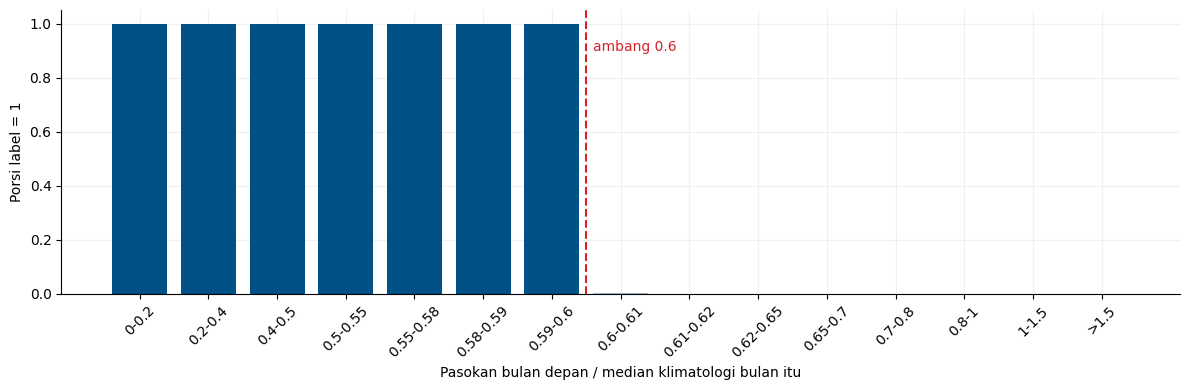

In [22]:
long = pd.concat([pd.DataFrame({'id': train.id, 'm': train.t - k, 'v': train[f'q_ws_cum_m3_lag{k}']}) for k in LAGS])
long = long[long.v >= 0]
ws_next = long.groupby(['id', 'm']).v.median().reindex(pd.MultiIndex.from_arrays([train.id, train.t + 1])).to_numpy()
clim_next_fixed = (train.clim_median_next * 10.0 ** clim_scale(train)).to_numpy()
ratio_next = ws_next / clim_next_fixed
has = np.isfinite(ratio_next)

stump = DecisionTreeClassifier(max_depth=1, random_state=CFG.SEED)
stump.fit(ratio_next[has].reshape(-1, 1), train.label.values[has])
print(export_text(stump, feature_names=['ws_next / clim_next']))
print(f'Stump accuracy: {stump.score(ratio_next[has].reshape(-1, 1), train.label.values[has]):.5f} on {has.sum()} rows')

bins = pd.cut(ratio_next, [0, .2, .4, .5, .55, .58, .59, .6, .61, .62, .65, .7, .8, 1, 1.5, np.inf])
rate = train.groupby(bins, observed=True).label.mean()
fig, ax = plt.subplots(figsize=(12, 4))
lab = [f'{iv.left:g}-{iv.right:g}' if np.isfinite(iv.right) else f'>{iv.left:g}' for iv in rate.index]
ax.bar(lab, rate.values, color=[CFG.BLUE if iv.right <= CFG.THR_RATIO else CFG.LIGHT for iv in rate.index])
ax.axvline(6.5, color=CFG.RED, ls='--')
ax.text(6.6, 0.9, 'ambang 0.6', color=CFG.RED)
ax.set_xlabel('Pasokan bulan depan / median klimatologi bulan itu')
ax.set_ylabel('Porsi label = 1')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '08_label_rule.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Label ditentukan oleh satu aturan: `label = 1` jika pasokan kumulatif bulan depan tidak lebih dari 0.6 kali median klimatologinya. *Stump* menemukan *threshold* di sekitar 0.60 dengan akurasi 99.99 persen, dan sisa ketidakcocokan berasal dari sel yang korup pada seluruh salinannya.
>
> Aturan ini sama dengan definisi resmi USGS pada *Integrated Water Availability Assessment* (2025): `SUI = 1 - (supply - consumptive use) / median supply bulanan` per HUC12, dan `SUI >= 0.4` setara dengan pasokan di bawah 0.6 kali median. Konsekuensinya, masalah ini adalah *forecasting* anomali pasokan satu bulan ke depan, dan semua fitur sebaiknya dinyatakan relatif terhadap klimatologi dan relatif terhadap *threshold* 0.6.

---

## Model Dasar dan SHAP

LightGBM di-*fit* pada kolom yang sudah diperbaiki tanpa rekayasa fitur. Kontribusi SHAP dihitung dengan `pred_contrib=True` pada sampel 20,000 baris untuk melihat kolom mentah mana yang dipakai model.

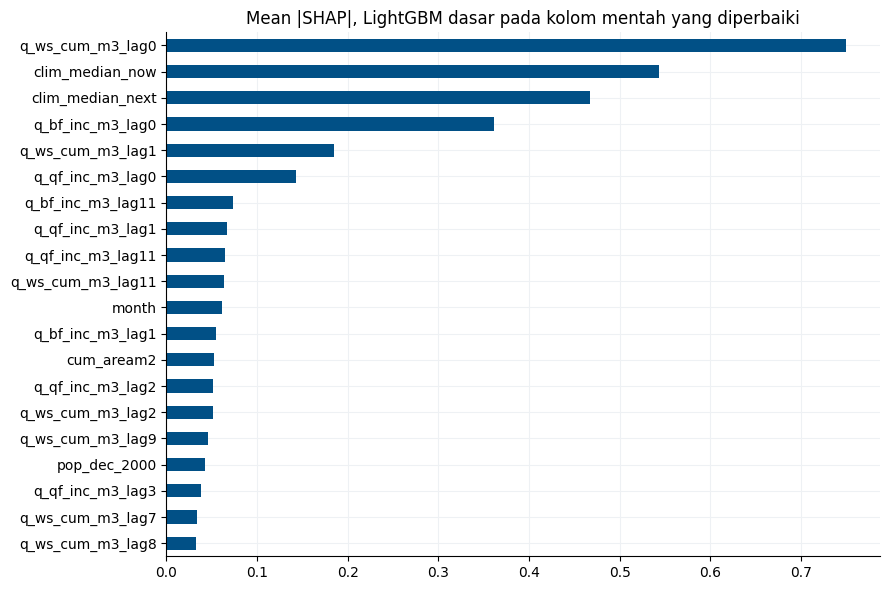

q_ws_cum_m3         0.346
q_bf_inc_m3         0.165
clim_median_now     0.145
q_qf_inc_m3         0.134
clim_median_next    0.124
q_ir_wd_inc_m3      0.021
month               0.016
cum_aream2          0.014
pop_dec_2000        0.011
pop_dec_2010        0.006
pop_acs_2020        0.005
q_ps_wd_inc_m3      0.005
pop_dec_2020        0.005
inc_aream2          0.003
q_th_wd_inc_m3      0.000


In [23]:
train_rep = full_repair(train)
train_rep['clim_median_now'] *= 10.0 ** clim_scale(train)
train_rep['clim_median_next'] *= 10.0 ** clim_scale(train)
base_cols = NUM_COLS + ['month']
base_model = lgb.train({**CFG.LGB_PARAMS, 'learning_rate': 0.05}, lgb.Dataset(train_rep[base_cols], train.label), 300)
sample = train_rep[base_cols].sample(20000, random_state=CFG.SEED)
shap_vals = base_model.predict(sample, pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(shap_vals).mean(0), base_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
shap_imp.head(20).sort_values().plot.barh(ax=ax, color=CFG.BLUE)
ax.set_title('Mean |SHAP|, LightGBM dasar pada kolom mentah yang diperbaiki')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '09_baseline_shap.png', dpi=120, bbox_inches='tight')
plt.show()
family_share = shap_imp.groupby(lambda c: c.rsplit('_lag', 1)[0]).sum()
print((family_share / family_share.sum()).sort_values(ascending=False).round(3).to_string())

> ### Insights
> Model dasar bergantung pada `q_ws_cum_m3_lag0`, `clim_median_next`, dan `clim_median_now`. Model harus mempelajari sendiri rasio antar kolom yang skalanya berbeda-beda antar sub-DAS, padahal pohon keputusan tidak efisien untuk membentuk rasio. Ini alasan utama fitur dibangun sebagai log-rasio terhadap klimatologi.
>
> Kolom pemakaian air hampir tidak berkontribusi, sesuai dengan hasil rekayasa balik label.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

EDA difokuskan pada pertanyaan yang langsung memengaruhi desain model: seberapa kuat persistensi kekeringan, bagaimana pola musiman dan antartahun, seberapa heterogen sub-DAS dan bagaimana kondisi hulu-hilir saling terkait, serta apakah pemakaian air ikut memicu *water stress*. EDA memakai data yang sudah diperbaiki (`train_rep`) agar pola tidak tertutup korupsi.

## Anomali Saat Ini dan Persistensi

Rasio pasokan bulan ini terhadap klimatologinya dihitung dari data yang sudah diperbaiki. Peluang label positif diplot terhadap rasio ini, dan sebaran margin log-rasio terhadap *threshold* 0.6 dibandingkan antara kedua kelas.

P(label=1 | now below 0.6 clim) = 0.628
P(label=1 | now above 0.6 clim) = 0.094
AP of the single score -margin_now = 0.6076


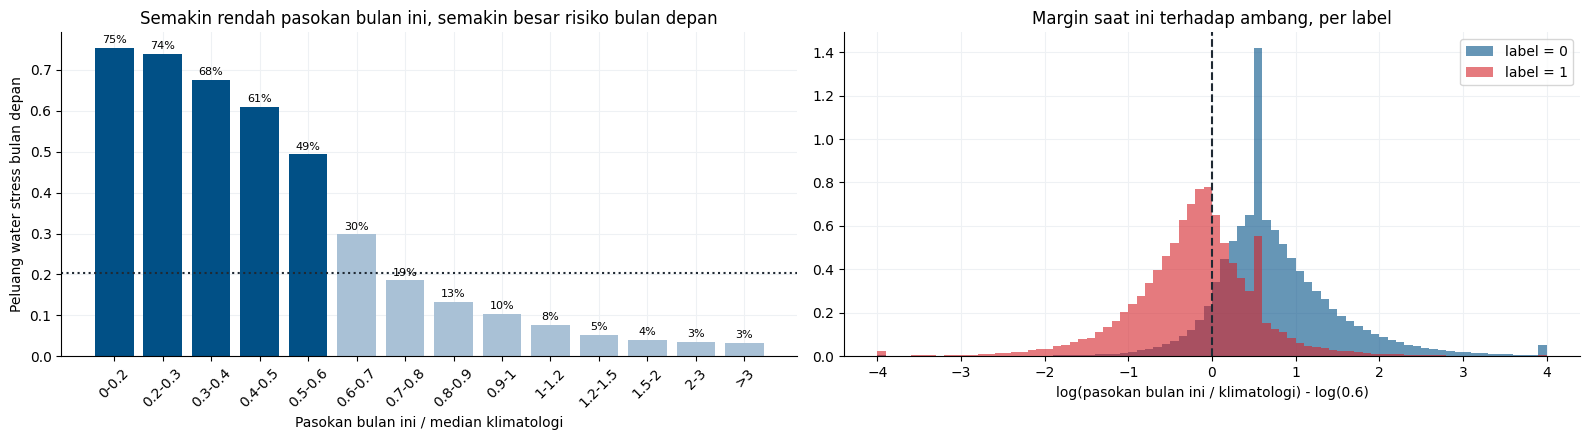

In [24]:
cur_ratio = np.log((train_rep.q_ws_cum_m3_lag0.clip(lower=0) + 1) / (train_rep.clim_median_now + 1))
margin_now = cur_ratio - np.log(CFG.THR_RATIO)
below_now = margin_now < 0
print(f'P(label=1 | now below 0.6 clim) = {train.label[below_now].mean():.3f}')
print(f'P(label=1 | now above 0.6 clim) = {train.label[~below_now].mean():.3f}')
print(f'AP of the single score -margin_now = {average_precision_score(train.label, -margin_now.fillna(0)):.4f}')

edges_r = [0, .2, .3, .4, .5, .6, .7, .8, .9, 1, 1.2, 1.5, 2, 3, np.inf]
cut_r = pd.cut(np.exp(cur_ratio), edges_r)
rate_r = train.groupby(cut_r, observed=True).label.mean()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
lab = [f'{iv.left:g}-{iv.right:g}' if np.isfinite(iv.right) else f'>{iv.left:g}' for iv in rate_r.index]
bars = ax[0].bar(lab, rate_r.values, color=[CFG.BLUE if iv.right <= CFG.THR_RATIO else CFG.LIGHT for iv in rate_r.index])
ax[0].bar_label(bars, labels=[f'{v:.0%}' for v in rate_r.values], padding=2, fontsize=8)
ax[0].axhline(train.label.mean(), ls=':', c=CFG.INK)
ax[0].set_xlabel('Pasokan bulan ini / median klimatologi')
ax[0].set_ylabel('Peluang water stress bulan depan')
ax[0].tick_params(axis='x', rotation=45)
ax[0].set_title('Semakin rendah pasokan bulan ini, semakin besar risiko bulan depan')
for lab_, col in [(0, CFG.BLUE), (1, CFG.RED)]:
    ax[1].hist(margin_now[train.label == lab_].clip(-4, 4), bins=80, alpha=.6, density=True, color=col, label=f'label = {lab_}')
ax[1].axvline(0, ls='--', c=CFG.INK)
ax[1].legend()
ax[1].set_xlabel('log(pasokan bulan ini / klimatologi) - log(0.6)')
ax[1].set_title('Margin saat ini terhadap ambang, per label')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '10_persistence.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Satu fitur persistensi saja mencapai AP sekitar 0.60, tiga kali lipat *baseline* acak. Jika pasokan bulan ini sudah di bawah 0.6 klimatologi, peluang bulan depan juga di bawah adalah sekitar 63 persen, dibanding sekitar 9 persen jika saat ini di atas. Kurva peluang turun tajam di sekitar margin nol, sehingga kesalahan paling banyak terjadi pada sub-DAS yang berada dekat *threshold*.
>
> Ini sejalan dengan literatur *streamflow drought forecasting* (Frontiers in Water, 2025) yang menemukan *persistence* sulit dikalahkan pada horizon pendek. Nilai tambah model ada pada kasus dekat *threshold*, yaitu memprediksi apakah anomali akan pulih atau memburuk.

---

## Musiman dan Variabilitas Antartahun

Laju label positif dibandingkan per bulan kalender *origin* dan per tahun hidrologi (September sampai Agustus) pada timeline hasil rekonstruksi.

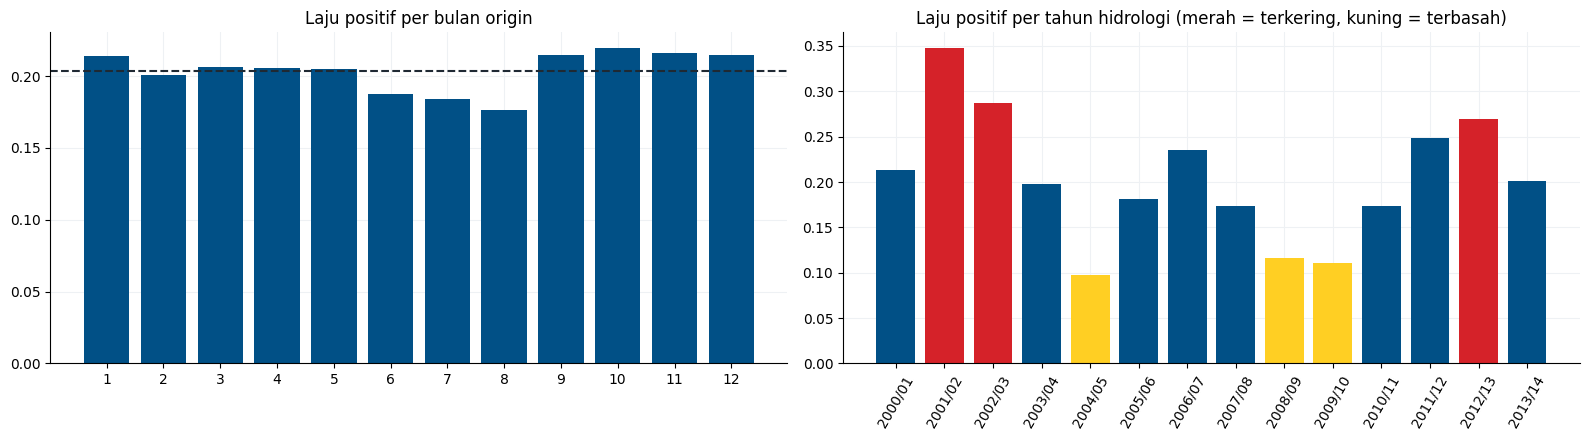

Yearly positive rate: {'2000/01': 0.214, '2001/02': 0.348, '2002/03': 0.287, '2003/04': 0.198, '2004/05': 0.097, '2005/06': 0.181, '2006/07': 0.235, '2007/08': 0.173, '2008/09': 0.116, '2009/10': 0.111, '2010/11': 0.174, '2011/12': 0.249, '2012/13': 0.269, '2013/14': 0.201}


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
by_month = train.groupby('month').label.mean()
ax[0].bar(by_month.index.astype(str), by_month.values, color=CFG.BLUE)
ax[0].axhline(train.label.mean(), ls='--', c=CFG.INK)
ax[0].set_title('Laju positif per bulan origin')
yearly = train.groupby(train.t // 12).label.mean()
year_lab = [f'{T0.year + k}/{str(T0.year + k + 1)[2:]}' for k in yearly.index]
cols_y = [CFG.RED if v >= yearly.quantile(.8) else CFG.YELLOW if v <= yearly.quantile(.2) else CFG.BLUE for v in yearly.values]
ax[1].bar(year_lab, yearly.values, color=cols_y)
ax[1].tick_params(axis='x', rotation=60)
ax[1].set_title('Laju positif per tahun hidrologi (merah = terkering, kuning = terbasah)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '11_seasonality.png', dpi=120, bbox_inches='tight')
plt.show()
print('Yearly positive rate:', dict(zip(year_lab, yearly.round(3))))

> ### Insights
> Laju positif per bulan relatif datar (sekitar 18 sampai 22 persen) karena label sudah dinormalisasi terhadap klimatologi bulan yang sama, sehingga tidak ada "musim *water stress*". Variasi antartahun jauh lebih besar, dari sekitar 10 persen pada tahun basah sampai 35 persen pada tahun kering.
>
> Karena *test* berasal dari tahun lain, prevalensi positif di *test* dapat berbeda jauh dari *train*. AP sensitif terhadap prevalensi, sehingga skor per *fold* diperkirakan bervariasi besar dan perbandingan model harus dilakukan berpasangan pada baris yang sama.

---

## Heterogenitas Sub-DAS dan Jaringan Sungai

Distribusi laju positif per sub-DAS diperiksa, lalu kondisi sub-DAS dibandingkan dengan sub-DAS hilirnya pada *origin* yang sama untuk melihat kekuatan korelasi spasial.

Per-HUC positive rate quantiles p5/p25/p50/p75/p95: [0.06, 0.137, 0.208, 0.268, 0.345]
HUCs with a downstream HUC in the same origin: 95.4%
Below-threshold state agrees with downstream HUC: 0.916


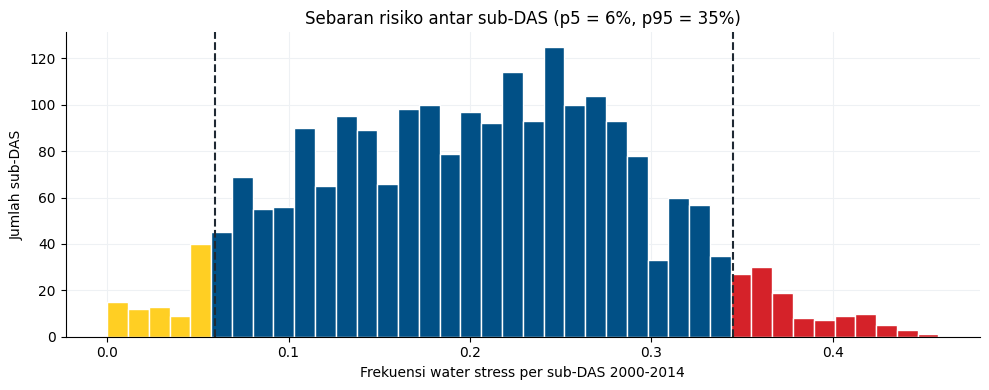

In [26]:
huc_rate = train.groupby('id').label.mean()
print('Per-HUC positive rate quantiles p5/p25/p50/p75/p95:', huc_rate.quantile([.05, .25, .5, .75, .95]).round(3).tolist())

state = pd.DataFrame({'id': train.id, 'origin_id': train.origin_id, 'below': below_now.values})
down = state.set_index(['id', 'origin_id']).below
down_state = down.reindex(pd.MultiIndex.from_arrays([train.to_id, train.origin_id])).to_numpy()
has_down = ~pd.isna(down_state)
print(f'HUCs with a downstream HUC in the same origin: {has_down.mean():.1%}')
agree = (down_state[has_down].astype(bool) == below_now.values[has_down]).mean()
print(f'Below-threshold state agrees with downstream HUC: {agree:.3f}')

fig, ax = plt.subplots(figsize=(10, 4))
lo_q, hi_q = huc_rate.quantile(.05), huc_rate.quantile(.95)
cnt, e_h = np.histogram(huc_rate.values, bins=40)
mid = (e_h[:-1] + e_h[1:]) / 2
ax.bar(mid, cnt, width=np.diff(e_h), color=[CFG.RED if c > hi_q else CFG.YELLOW if c < lo_q else CFG.BLUE for c in mid],
       edgecolor='white')
for q in (lo_q, hi_q):
    ax.axvline(q, ls='--', c=CFG.INK)
ax.set_xlabel('Frekuensi water stress per sub-DAS 2000-2014')
ax.set_ylabel('Jumlah sub-DAS')
ax.set_title(f'Sebaran risiko antar sub-DAS (p5 = {lo_q:.0%}, p95 = {hi_q:.0%})')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '12_huc_heterogeneity.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Laju positif per sub-DAS menyebar dari 6 sampai 35 persen, tetapi sebaran ini lebih mencerminkan tahun-tahun kering yang dialami daripada sifat tetap sub-DAS. *Target encoding* per sub-DAS sudah diuji dan menurunkan CV AP dari 0.7008 ke 0.5879, sehingga identitas sub-DAS tidak dipakai sebagai fitur.
>
> Status di bawah *threshold* sangat sejalan dengan sub-DAS hilirnya (sekitar 91 persen). Kekeringan bersifat regional, sehingga agregat kondisi basin pada *origin* yang sama layak dijadikan fitur.

---

## Pemakaian Air terhadap Water Stress

Hipotesis yang wajar adalah sub-DAS dengan pemakaian air tinggi lebih sering mengalami *water stress*. Pemakaian (irigasi, *thermoelectric*, *public supply*) dibandingkan terhadap pasokan **normal** bulan target, bukan pasokan bulan ini, agar efek kekeringan tidak ikut terhitung sebagai efek pemakaian. Peluang *water stress* per desil intensitas pemakaian dibandingkan dengan per desil defisit pasokan.

AUC water-use intensity 0.507 | AUC supply deficit 0.849


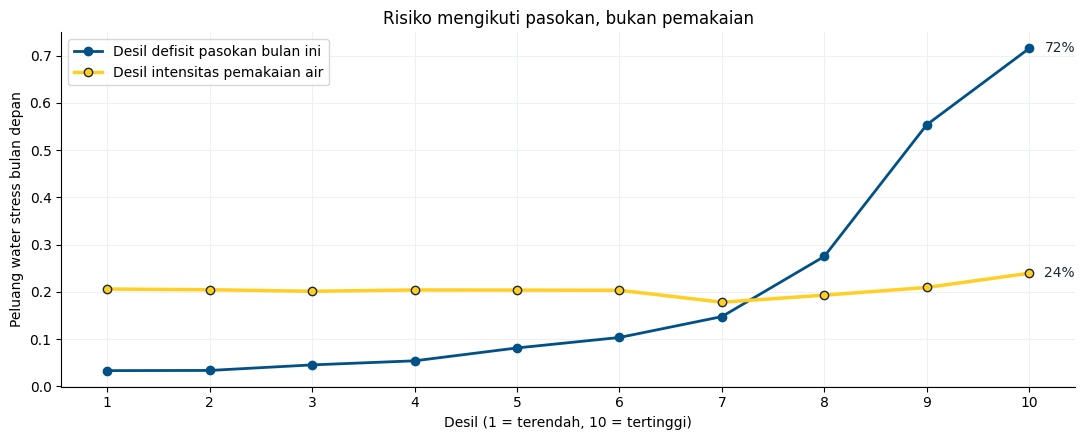

In [27]:
use0 = sum(train_rep[f'{f}_lag0'].abs() for f in ['q_ir_wd_inc_m3', 'q_th_wd_inc_m3', 'q_ps_wd_inc_m3'])
use_int = np.log1p(use0 / (train_rep.clim_median_next + 1))
ok = use_int.notna() & margin_now.notna()
dec_use = pd.qcut(use_int[ok].rank(method='first'), 10, labels=False) + 1
dec_def = pd.qcut((-margin_now[ok]).rank(method='first'), 10, labels=False) + 1
r_use = train.label[ok].groupby(dec_use.values).mean()
r_def = train.label[ok].groupby(dec_def.values).mean()
print(f'AUC water-use intensity {roc_auc_score(train.label[ok], use_int[ok]):.3f} | '
      f'AUC supply deficit {roc_auc_score(train.label[ok], -margin_now[ok]):.3f}')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(r_def.index, r_def.values, marker='o', color=CFG.BLUE, lw=2, label='Desil defisit pasokan bulan ini')
ax.plot(r_use.index, r_use.values, marker='o', color=CFG.YELLOW, mec=CFG.INK, lw=2.5, label='Desil intensitas pemakaian air')
for s_, c in [(r_def, CFG.INK), (r_use, CFG.INK)]:
    ax.text(10.15, s_.values[-1], f'{s_.values[-1]:.0%}', va='center', color=c)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Desil (1 = terendah, 10 = tertinggi)')
ax.set_ylabel('Peluang water stress bulan depan')
ax.legend()
ax.set_title('Risiko mengikuti pasokan, bukan pemakaian')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '13_water_use.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Hipotesis pemakaian air tidak didukung data. Peluang *water stress* hampir datar di seluruh desil intensitas pemakaian (AUC sekitar 0.51, setara menebak), sedangkan desil defisit pasokan menaikkan risiko dari sekitar 3 persen ke 72 persen (AUC sekitar 0.85).
>
> Hasil ini konsisten dengan definisi label: pemakaian konsumtif memang ada di rumus SUI, tetapi nilainya sangat kecil dibanding pasokan. Fitur pemakaian air tetap dimasukkan ke model sebagai kandidat, dan kontribusinya diukur ulang di bagian Evaluasi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Rekayasa Fitur <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Semua fitur dibangun dari satu prinsip: posisi pasokan saat ini terhadap klimatologinya, arah pergerakannya, dan kondisi regional. Bagian ini memuat tabel klimatologi, *Feature Creation*, *Discretization*, *Clipping*, *Feature Encoding*, dan *Feature Selection*. Semua fitur aliran berbentuk rasio di dalam baris yang sama, sehingga kebal terhadap faktor skala acak per sub-DAS di *test*.

## Tabel Klimatologi dan Pengisian Celah

Klimatologi setiap sub-DAS untuk 12 bulan kalender dikumpulkan dari `clim_median_now` dan `clim_median_next` seluruh baris, per split. Setiap sub-DAS *test* hanya mengetahui 8 bulan (bulan *origin* 2, 4, 10, 12 dan bulan berikutnya). Untuk sub-DAS yang juga ada di *train*, bentuk musiman *train* dipindahkan dengan faktor skala sub-DAS tersebut. Untuk sub-DAS baru, bulan yang hilang diisi dengan bentuk musiman 15 sub-DAS lengkap yang paling mirip pada bulan yang diketahui (kNN analog).

In [28]:
def fill_clim_knn(C, k=15, ref=None):
    ref = np.log1p((C if ref is None else ref).dropna())
    out = C.copy()
    for pattern, grp in C[C.isna().any(axis=1)].groupby(lambda i: tuple(C.loc[i].isna())):
        known = [m for m, miss in zip(C.columns, pattern) if not miss]
        if len(known) < 3:
            continue
        R = ref.sub(ref[known].mean(1), axis=0)
        Q = np.log1p(grp[known])
        lvl = Q.mean(1)
        _, idx = NearestNeighbors(n_neighbors=k).fit(R[known].values).kneighbors(Q.sub(lvl, axis=0).values)
        est = pd.DataFrame(np.expm1(R.values[idx].mean(1) + lvl.values[:, None]), grp.index, C.columns)
        out.loc[grp.index] = grp.fillna(est)
    return out

def clim_table(df, fill=True, ref=None):
    e = 10.0 ** clim_scale(df)
    a = pd.DataFrame({'id': df.id, 'm': df.month, 'c': df.clim_median_now * e})
    b = pd.DataFrame({'id': df.id, 'm': df.month % 12 + 1, 'c': df.clim_median_next * e})
    C = pd.concat([a, b]).groupby(['id', 'm']).c.median().unstack().reindex(columns=range(1, 13))
    if not fill:
        return C
    if ref is not None:
        shared = C.index.intersection(ref.dropna().index)
        R = ref.loc[shared]
        k = np.log(C.loc[shared] / R).median(axis=1)
        C.loc[shared] = C.loc[shared].fillna(R.mul(np.exp(k), axis=0))
    return fill_clim_knn(C, ref=ref)

CLIM_TR = clim_table(train)
CLIM_TE = clim_table(test, ref=CLIM_TR)
raw_te = clim_table(test, fill=False)
seen_mask = raw_te.index.isin(CLIM_TR.index)
print('Test HUCs with missing clim months:', int(raw_te.isna().any(axis=1).sum()))
print('  of which seen in train (shape transfer):', int((raw_te.isna().any(axis=1) & seen_mask).sum()))
print('  of which unseen (kNN analog):', int((raw_te.isna().any(axis=1) & ~seen_mask).sum()))
print('Missing cells after fill: train', int(CLIM_TR.isna().sum().sum()), '| test', int(CLIM_TE.isna().sum().sum()))

Test HUCs with missing clim months: 2982
  of which seen in train (shape transfer): 2196
  of which unseen (kNN analog): 786
Missing cells after fill: train 48 | test 0


Metode pengisian divalidasi dengan mensimulasikan kondisi *test* pada sub-DAS *train*: hanya empat baris dengan bulan *origin* 2, 4, 10, dan 12 yang dipakai, lalu klimatologi Juni sampai September diestimasi dan dibandingkan dengan nilai sebenarnya. Interpolasi siklik dipakai sebagai pembanding.

In [29]:
full_known = CLIM_TR.loc[clim_table(train, fill=False).dropna().index]
sim = (train[train.id.isin(full_known.index) & train.month.isin([2, 4, 10, 12])]
       .sample(frac=1, random_state=CFG.SEED).drop_duplicates(['id', 'month']))
part = clim_table(sim, fill=False)
miss = part.isna()
truth_tab = full_known.loc[part.index]

def cyclic_fill(P):
    L = np.log1p(P)
    T = pd.concat([L, L, L], axis=1)
    T.columns = range(36)
    T = T.T.interpolate(limit_direction='both').T
    return np.expm1(T.iloc[:, 12:24].set_axis(P.columns, axis=1))

for name, P in [('cyclic interpolation', cyclic_fill(part)), ('kNN analog', fill_clim_knn(part, ref=full_known))]:
    err = (np.log1p(P) - np.log1p(truth_tab))[miss].stack().dropna()
    print(f'{name:22s} median |log err| {err.abs().median():.3f}  within 20% {(err.abs() < np.log(1.2)).mean():.3f}  bias {err.median():+.3f}')

cyclic interpolation   median |log err| 0.272  within 20% 0.382  bias +0.115
kNN analog             median |log err| 0.121  within 20% 0.632  bias -0.000


> ### Insights
> Tanpa pengisian, fitur anomali untuk lag bulan Juni sampai September bernilai NaN pada 7 sampai 26 persen baris *test*, sedangkan di *train* hampir tidak pernah NaN, sehingga model akan diuji pada pola *missing* yang tidak pernah dilihat saat pelatihan.
>
> Interpolasi siklik secara teori masuk akal untuk kurva musiman, tetapi galatnya besar (median sekitar 0.27 log) dan bias positif karena melewatkan lembah aliran musim panas. kNN analog menurunkan galat menjadi sekitar 0.13 tanpa bias, sehingga metode ini yang dipakai.

---

## Feature Creation

Fitur dibangun dalam lima kelompok: statis (luas, kepadatan penduduk, sub-DAS hulu), anomali log-rasio terhadap klimatologi untuk 12 lag beserta ringkasan 3, 6, dan 12 bulan (analog indeks kekeringan SSI-3/6/12), margin persistensi terhadap *threshold* 0.6, skenario kering berbasis resesi *baseflow*, dan kondisi jaringan sungai pada *origin* yang sama. Kolom `aux_fake_mm_*` dipakai untuk mengisi luas area yang hilang. Fitur *train* dan *test* dibangun terpisah dengan klimatologi masing-masing.

In [30]:
THR = np.log(CFG.THR_RATIO)
EPS = 1.0

def basin_root(id_to):
    nxt = id_to.to_dict()
    root = {}
    for h in nxt:
        path, cur = [], h
        while cur in nxt and cur not in root and cur not in path and nxt[cur] in nxt:
            path.append(cur)
            cur = nxt[cur]
        r = root.get(cur, cur)
        for p in path:
            root[p] = r
        root.setdefault(h, r)
    return pd.Series(root)

def build_features(df, C, basin, x=None):
    x = full_repair(df) if x is None else x
    inc = df.inc_aream2.abs().fillna(df[['aux_fake_mm_04', 'aux_fake_mm_09', 'aux_fake_mm_14']].median(axis=1) * 1e4)
    cum = df.cum_aream2.abs().fillna(inc)
    L = lambda f, k: x[f'{f}_lag{k}'].clip(lower=0)
    F = pd.DataFrame(index=df.index)
    F['month'] = df.month
    F['m_sin'] = np.sin(2 * np.pi * df.month / 12)
    F['m_cos'] = np.cos(2 * np.pi * df.month / 12)

    F['log_inc_area'], F['log_cum_area'] = np.log1p(inc), np.log1p(cum)
    F['headwater'] = np.isclose(inc, cum, rtol=1e-6).astype(int)
    F['log_pop_dens'] = np.log1p(df.pop_acs_2020.abs() / (inc / 1e6 + 1e-3))
    F['pop_growth'] = np.log1p(df.pop_dec_2020.abs()) - np.log1p(df.pop_dec_2000.abs())

    ci = C.index.get_indexer(df.id)
    Cm = C.to_numpy()
    clim_at = lambda month: np.where(ci >= 0, Cm[ci, month - 1], np.nan)
    clim_now, clim_next = clim_at(df.month.values), clim_at(df.month.values % 12 + 1)
    F['seas_step'] = np.log((clim_next + EPS) / (clim_now + EPS))
    F['clim_cv'] = np.nanstd(np.log1p(Cm), axis=1)[ci]

    A = np.column_stack([np.log((L('q_ws_cum_m3', k) + EPS) / (clim_at((df.month.values - 1 - k) % 12 + 1) + EPS))
                         for k in LAGS])
    for k in LAGS:
        F[f'anom{k}'] = A[:, k]
    F['anom_mean3'], F['anom_mean6'], F['anom_mean12'] = A[:, :3].mean(1), A[:, :6].mean(1), A.mean(1)
    F['anom_min6'], F['anom_std12'] = A[:, :6].min(1), A.std(1)

    ws0, bf0, qf0 = L('q_ws_cum_m3', 0), L('q_bf_inc_m3', 0), L('q_qf_inc_m3', 0)
    inflow0 = (ws0 - bf0 - qf0).clip(lower=0)
    F['margin_raw_persist'] = np.log((ws0 + EPS) / (clim_next + EPS)) - THR
    rec_raw = (bf0 + EPS) / (L('q_bf_inc_m3', 1) + EPS)
    rec = rec_raw.clip(0.2, 1.5)
    F['bf_recession_raw'] = np.log(rec_raw)
    F['bf_recession'] = np.log(rec)
    F['margin_dry'] = np.log((bf0 * rec + inflow0 + EPS) / (clim_next + EPS)) - THR
    F['qf_share0'] = qf0 / (ws0 + EPS)
    F['up_share0'] = inflow0 / (ws0 + EPS)
    F['bf_share0'] = bf0 / (ws0 + EPS)
    for k in (1, 2, 3):
        F[f'ws_trend{k}'] = np.log((ws0 + EPS) / (L('q_ws_cum_m3', k) + EPS))
    F['bf_trend1'] = np.log((bf0 + EPS) / (L('q_bf_inc_m3', 1) + EPS))
    F['qf_mean3_share'] = sum(L('q_qf_inc_m3', k) for k in range(3)) / (sum(L('q_ws_cum_m3', k) for k in range(3)) + EPS)

    use0 = L('q_ir_wd_inc_m3', 0) + L('q_th_wd_inc_m3', 0) + L('q_ps_wd_inc_m3', 0)
    F['use_ratio0'] = np.log1p(use0 / (ws0 + EPS))
    F['use_clim_next'] = np.log1p(use0 / (clim_next + EPS))
    F['ir_share'] = L('q_ir_wd_inc_m3', 0) / (use0 + EPS)

    key = pd.DataFrame({'id': df.id.values, 'to_id': df.to_id.values, 'origin_id': df.origin_id.values,
                        'a0': A[:, 0], 'below': A[:, 0] < THR})
    key['basin'] = key.id.map(basin)
    a0 = key.drop_duplicates(['id', 'origin_id']).set_index(['id', 'origin_id']).a0
    F['down_anom0'] = a0.reindex(pd.MultiIndex.from_arrays([key.to_id, key.origin_id])).to_numpy()
    up = key.groupby(['to_id', 'origin_id']).a0.mean()
    F['up_anom0'] = up.reindex(pd.MultiIndex.from_arrays([key.id, key.origin_id])).to_numpy()
    g = key.groupby(['basin', 'origin_id'])
    F['basin_anom0'] = g.a0.transform('mean').to_numpy()
    F['basin_below0'] = g.below.transform('mean').to_numpy()
    F['basin_size'] = g.a0.transform('size').to_numpy()
    go = key.groupby('origin_id')
    F['origin_anom0'] = go.a0.transform('mean').to_numpy()
    F['origin_below0'] = go.below.transform('mean').to_numpy()
    F['anom0_vs_basin'] = A[:, 0] - F['basin_anom0']
    return F.replace([np.inf, -np.inf], np.nan)

id_to = pd.concat([train[['id', 'to_id']], test[['id', 'to_id']]]).drop_duplicates('id').set_index('id').to_id
BASIN = basin_root(id_to)
REP_TR, REP_TE = full_repair(train), full_repair(test)
X_train_full = build_features(train, CLIM_TR, BASIN, REP_TR).reset_index(drop=True)
X_test_full = build_features(test, CLIM_TE, BASIN, REP_TE).reset_index(drop=True)
y = train.label.values
print('Features created:', X_train_full.shape[1], '| basins:', BASIN.nunique())

Features created: 50 | basins: 148


---

## Feature Creation: Peluang Transisi Klimatologis

Kerugian AP terbesar ada pada baris yang sedang kering: sekitar 38 persen di antaranya pulih bulan depan dan model sulit membedakannya. Fitur berikut memakai riwayat pertumbuhan pasokan bulanan sub-DAS itu sendiri, `g = log(ws(m+1) / ws(m))`, untuk transisi bulan kalender yang sama dengan target. Pertumbuhan yang dibutuhkan agar tetap di atas *threshold* adalah `log(0.6 clim_next / ws0)`, dan fitur utamanya adalah fraksi tahun historis yang melampaui angka itu. Fitur ini tidak memakai label, berbentuk rasio, dan mengecualikan tahun dalam jarak 12 bulan dari target agar tidak bocor.

In [31]:
TRANS_COLS = ['trans_p_exceed', 'trans_margin_med', 'trans_g_std', 'trans_n']

def transition_features(query, history, min_hist=CFG.MIN_HIST):
    parts = []
    for k in range(11):
        a = history[f'q_ws_cum_m3_lag{k}'].abs().values
        b = history[f'q_ws_cum_m3_lag{k + 1}'].abs().values
        parts.append(pd.DataFrame({'id': history.id.values, 'T': history.t.values - k,
                                   'cm': (history.month.values - 1 - k) % 12 + 1, 'g': np.log((a + 1) / (b + 1))}))
    G = pd.concat(parts).dropna().groupby(['id', 'cm', 'T']).g.median().reset_index()
    hist = {key: grp[['T', 'g']].to_numpy() for key, grp in G.groupby(['id', 'cm'])}
    req = np.log((CFG.THR_RATIO * query['_clim_next'].values + 1) / (query.q_ws_cum_m3_lag0.abs().values + 1))
    out = np.full((len(query), 4), np.nan)
    for j, (hid, cm, t) in enumerate(zip(query.id.values, query.month.values % 12 + 1, query.t.values)):
        H = hist.get((hid, cm))
        if H is None:
            continue
        H = H[np.abs(H[:, 0] - (t + 1)) > 12, 1]
        if len(H) >= min_hist:
            out[j] = [(H > req[j]).mean(), np.median(H) - req[j], H.std(), len(H)]
    return pd.DataFrame(out, index=query.index, columns=TRANS_COLS)

def with_clim_next(df, C, x=None):
    out = (full_repair(df) if x is None else x).copy()
    idx = C.index.get_indexer(df.id)
    out['_clim_next'] = np.where(idx >= 0, C.to_numpy()[idx, df.month.values % 12], np.nan)
    return out

tr_q = with_clim_next(train, CLIM_TR, REP_TR)
te_q = with_clim_next(test, CLIM_TE, REP_TE)
te_q['t'] = 10_000 + te_q.origin_id.rank(method='dense').values * 100
T_train = transition_features(tr_q, tr_q).reset_index(drop=True).astype('float32')
T_test = transition_features(te_q, pd.concat([tr_q, te_q])).reset_index(drop=True).astype('float32')
seen_test = test.id.isin(set(train.id)).values
print(f'coverage train {T_train.trans_p_exceed.notna().mean():.3f} | test seen HUCs '
      f'{T_test.trans_p_exceed.notna().values[seen_test].mean():.3f} | test unseen HUCs '
      f'{T_test.trans_p_exceed.notna().values[~seen_test].mean():.3f}')

m0 = X_train_full.anom0.values - THR
for zone, mask in [('dry', m0 < 0), ('onset', (m0 >= 0) & (m0 < .5)), ('all', np.ones(len(m0), bool))]:
    ok = mask & T_train.trans_p_exceed.notna().values
    a_new = roc_auc_score(y[ok], -T_train.trans_p_exceed.values[ok])
    a_old = roc_auc_score(y[ok], -X_train_full.margin_raw_persist.fillna(0).values[ok])
    print(f'{zone:5s} univariate AUC  trans_p_exceed {a_new:.3f}  vs margin_raw_persist {a_old:.3f}')

coverage train 1.000 | test seen HUCs 1.000 | test unseen HUCs 0.000
dry   univariate AUC  trans_p_exceed 0.700  vs margin_raw_persist 0.594
onset univariate AUC  trans_p_exceed 0.782  vs margin_raw_persist 0.705
all   univariate AUC  trans_p_exceed 0.886  vs margin_raw_persist 0.838


> ### Insights
> Secara univariat, peluang transisi lebih kuat daripada margin persistensi di semua zona. Fitur ini membawa variabilitas pertumbuhan khas tiap sub-DAS: sungai yang ditopang *baseflow* jarang melonjak, sedangkan sungai *flashy* sering pulih mendadak.
>
> Di model, fitur riwayat menaikkan AP sub-DAS yang dikenal tetapi menurunkan sub-DAS baru, karena model bergantung pada fitur yang hampir selalu tersedia saat pelatihan. Karena itu fitur ini hanya dipakai lewat **model hibrida**: model dengan riwayat untuk sub-DAS yang dikenal, model tanpa riwayat untuk sub-DAS baru. Sub-DAS *test* dengan kurang dari 5 tahun riwayat otomatis memakai model tanpa riwayat.

---

## Discretization

Dua fitur diskret merangkum riwayat kekeringan dalam kategori yang mudah dibaca: jumlah bulan dari 12 bulan terakhir yang berada di bawah *threshold*, dan panjang deret kering berturut-turut yang berakhir pada bulan ini (durasi kekeringan). Peluang pulih juga dipetakan terhadap durasi kekeringan dan bulan target.

,0,1,2,3,4,5,6,7,8,9,10,11,12
label_rate,0.094,0.492,0.599,0.655,0.714,0.764,0.781,0.808,0.837,0.78,0.783,0.758,0.844
rows,293290.000,27717.000,13845.000,8405.000,5575.000,4010.000,3072.000,2393.000,1958.000,1628.00,1281.000,1018.000,4736.000


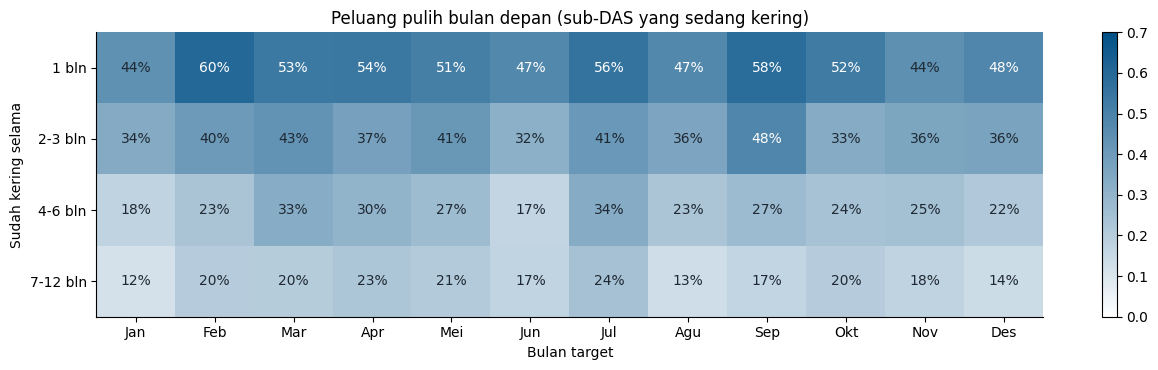

In [32]:
def drought_counts(A):
    below = A < THR
    run = np.cumprod(below, axis=1).sum(1)
    return below.sum(1), run

def add_discrete(X_):
    X_['n_below12'], X_['drought_run'] = drought_counts(X_[[f'anom{k}' for k in LAGS]].to_numpy())
    return X_

for X_ in (X_train_full, X_test_full):
    add_discrete(X_)

display(pd.DataFrame({'label_rate': pd.Series(y).groupby(X_train_full.drought_run.values).mean(),
                      'rows': pd.Series(y).groupby(X_train_full.drought_run.values).size()}).T.round(3))

dry = X_train_full.anom0.values < THR
MN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
bucket = pd.cut(X_train_full.drought_run.values[dry], [0, 1, 3, 6, 12], labels=['1 bln', '2-3 bln', '4-6 bln', '7-12 bln'])
H = pd.DataFrame({'m': train.month.values[dry] % 12 + 1, 'b': bucket, 'r': 1 - y[dry]}).pivot_table(
    index='b', columns='m', values='r', observed=True)
fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(H.to_numpy(), cmap=LinearSegmentedColormap.from_list('team', ['#FFFFFF', CFG.BLUE]), vmin=0, vmax=.7, aspect='auto')
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f'{H.iat[i, j]:.0%}', ha='center', va='center', color='white' if H.iat[i, j] > .45 else CFG.INK)
ax.set_xticks(range(12), MN)
ax.set_yticks(range(H.shape[0]), H.index)
ax.grid(False)
ax.set_xlabel('Bulan target')
ax.set_ylabel('Sudah kering selama')
ax.set_title('Peluang pulih bulan depan (sub-DAS yang sedang kering)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '14_recovery_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Peluang positif naik tajam di bulan pertama kekeringan (sekitar 9 ke 49 persen) lalu melandai setelah sekitar 6 bulan (78 sampai 84 persen). Sub-DAS yang baru 1 bulan kering punya peluang pulih sekitar 51 persen, sedangkan yang sudah 7 sampai 12 bulan hanya sekitar 18 persen, di bulan apa pun. Fitur ini menangkap memori hidrologis (air tanah dan *baseflow*) yang tidak terlihat dari satu lag saja.

---

## Clipping

Rasio resesi *baseflow* dapat meledak ketika *baseflow* bulan sebelumnya mendekati nol. Rasio ini dipotong ke rentang fisik 0.2 sampai 1.5 sebelum dipakai dalam skenario kering (`margin_dry`), lalu kolom mentahnya dibuang saat seleksi fitur.

                     count   mean    std     min   0.1%     1%    50%    99%  \
bf_recession_raw  368928.0 -0.016  0.555 -22.523 -2.275 -1.062 -0.052  1.618   
bf_recession      368928.0 -0.070  0.314  -1.609 -1.609 -1.062 -0.052  0.405   

                  99.9%     max  
bf_recession_raw  3.374  22.475  
bf_recession      0.405   0.405  


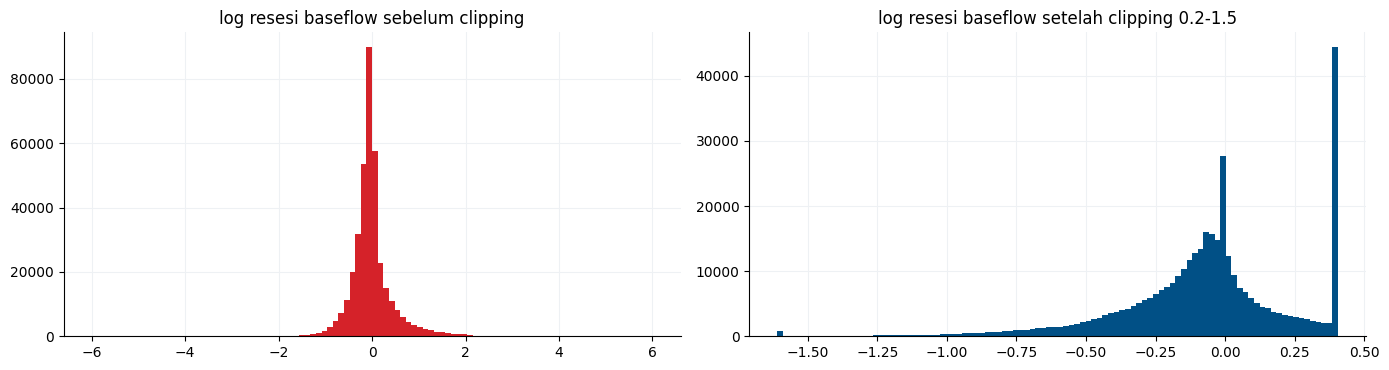

In [33]:
print(X_train_full[['bf_recession_raw', 'bf_recession']].describe(percentiles=[.001, .01, .99, .999]).round(3).T)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].hist(X_train_full.bf_recession_raw.dropna().clip(-6, 6), bins=100, color=CFG.RED)
ax[0].set_title('log resesi baseflow sebelum clipping')
ax[1].hist(X_train_full.bf_recession.dropna(), bins=100, color=CFG.BLUE)
ax[1].set_title('log resesi baseflow setelah clipping 0.2-1.5')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '15_clipping.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Rasio resesi mentah memiliki ekor ekstrem. Tanpa pemotongan, skenario kering akan memproyeksikan kenaikan pasokan puluhan kali lipat yang tidak fisik. Pemotongan hanya memengaruhi ekor distribusi, sehingga pohon keputusan tidak kehilangan informasi, tetapi fitur turunan `margin_dry` menjadi stabil.

---

## Feature Encoding

Bulan dikodekan dua kali: sebagai bilangan bulat untuk *split* pohon dan sebagai pasangan sin/cos agar Desember dan Januari berdekatan. ID sub-DAS, `to_id`, dan `origin_id` tidak dikodekan sebagai fitur.

In [34]:
display(X_train_full[['month', 'm_sin', 'm_cos']].drop_duplicates().sort_values('month').round(3).T)

,25,23,4,9,16,18,7,5,14,0,3,11
month,1.000,2.000,3.0,4.000,5.000,6.0,7.000,8.000,9.0,10.000,11.000,12.0
m_sin,0.500,0.866,1.0,0.866,0.500,0.0,-0.500,-0.866,-1.0,-0.866,-0.500,-0.0
m_cos,0.866,0.500,0.0,-0.500,-0.866,-1.0,-0.866,-0.500,-0.0,0.500,0.866,1.0


> ### Insights
> *Target encoding* per sub-DAS sudah diuji dengan skema *fold* yang sama (dihitung hanya dari bagian *train* setiap *fold*, dengan *smoothing*) dan menurunkan CV AP dari 0.7008 ke 0.5879 pada keempat *fold*. Laju kekeringan sebuah sub-DAS tidak stasioner antar tahun, sehingga *encoding* historis membuat model menghafal identitas sub-DAS. `origin_id` adalah ID acak tanpa urutan, sehingga tidak boleh dipakai sebagai angka.

---

## Feature Selection

Seleksi memakai tiga bukti: kekuatan univariat (AP dan AUC per fitur), redundansi (korelasi Spearman terkelompok), dan *drift train* ke *test* (*adversarial validation*). Keputusan akhir diambil dari *ablation* CV pada skema *fold* yang meniru *test*.

In [35]:
uni = []
for c in X_train_full.columns:
    v = X_train_full[c].fillna(X_train_full[c].median())
    a = roc_auc_score(y, v)
    uni.append((c, max(a, 1 - a), average_precision_score(y, -v if a < .5 else v),
                X_train_full[c].isna().mean(), X_test_full[c].isna().mean()))
uni = pd.DataFrame(uni, columns=['feature', 'AUC', 'AP', 'nan_train', 'nan_test']).sort_values('AP', ascending=False)
display(uni.head(15).round(4))
display(uni.tail(6).round(4))

,feature,AUC,AP,nan_train,nan_test
10,anom0,0.8493,0.6084,0.0018,0.0000
22,anom_mean3,0.8261,0.5840,0.0018,0.0000
42,down_anom0,0.8170,0.5601,0.0460,0.0496
44,basin_anom0,0.8168,0.5515,0.0009,0.0000
27,margin_raw_persist,0.8389,0.5510,0.0018,0.0000
51,drought_run,0.7769,0.5383,0.0000,0.0000
45,basin_below0,0.8115,0.5383,0.0000,0.0000
23,anom_mean6,0.7943,0.5356,0.0018,0.0000
11,anom1,0.7833,0.5018,0.0018,0.0000
30,margin_dry,0.8339,0.4585,0.0018,0.0000


,feature,AUC,AP,nan_train,nan_test
41,ir_share,0.5093,0.2094,0.0000,0.0000
0,month,0.5041,0.2078,0.0000,0.0000
3,log_inc_area,0.5070,0.2074,0.0082,0.0087
1,m_sin,0.5007,0.2059,0.0000,0.0000
6,log_pop_dens,0.5041,0.2021,0.0244,0.0262
46,basin_size,0.5062,0.2001,0.0000,0.0000


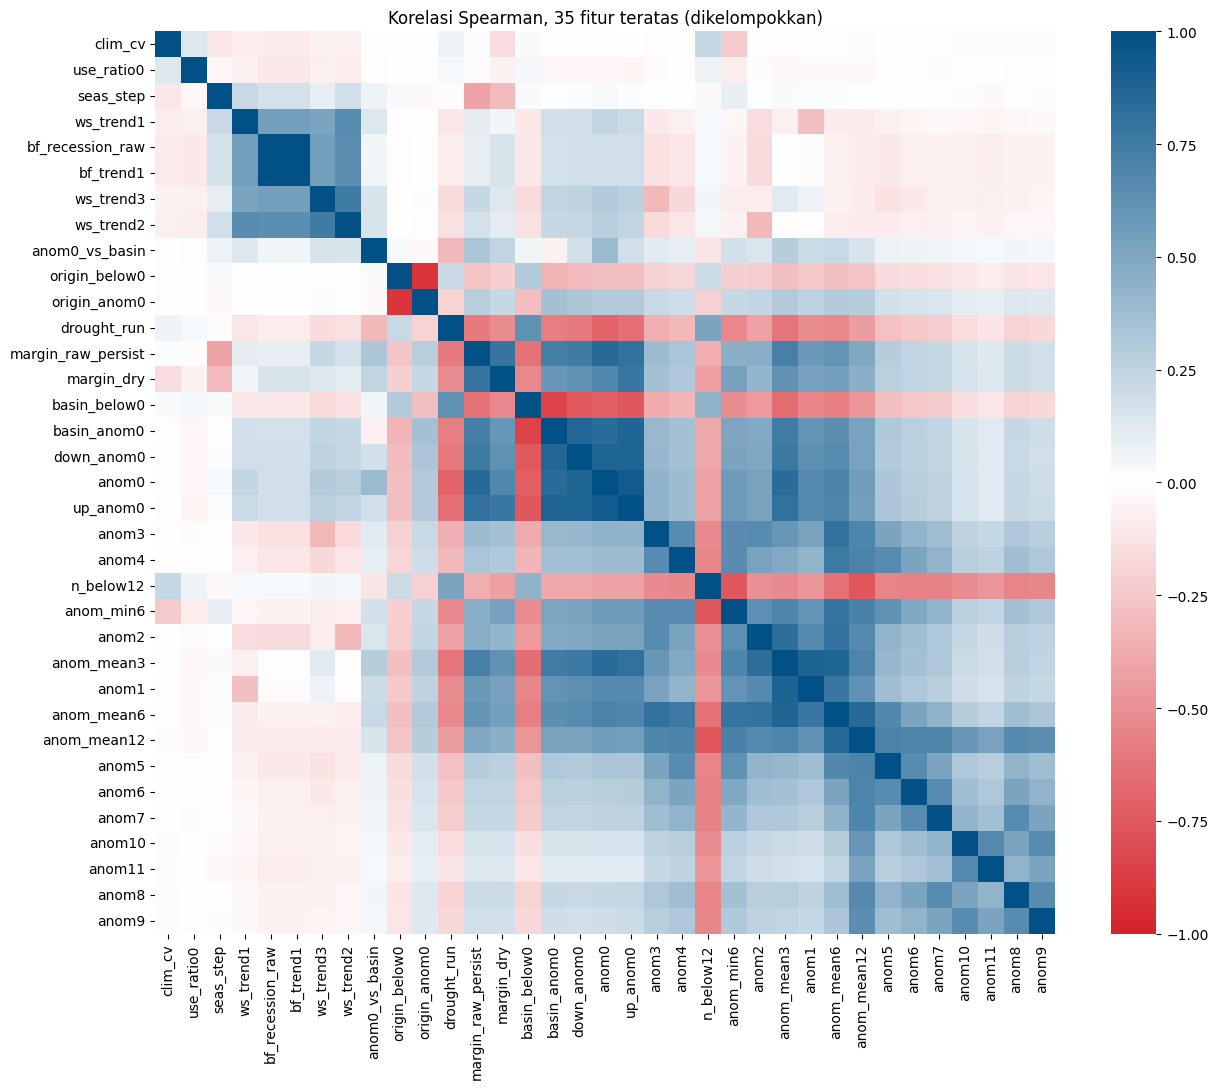

bf_recession_raw  bf_trend1       1.000
anom0             up_anom0        0.935
origin_below0     origin_anom0   -0.913


In [36]:
top = uni.feature.head(35).tolist()
corr = X_train_full[top].corr(method='spearman').fillna(0)
order = hierarchy.leaves_list(hierarchy.linkage(1 - corr.abs().values[np.triu_indices(len(top), 1)], 'average'))
corr = corr.iloc[order, order]
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap=LinearSegmentedColormap.from_list('div', [CFG.RED, '#FFFFFF', CFG.BLUE]), center=0, vmin=-1, vmax=1)
plt.title('Korelasi Spearman, 35 fitur teratas (dikelompokkan)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '16_corr_matrix.png', dpi=120, bbox_inches='tight')
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(pairs[pairs.abs() > 0.9].sort_values(ascending=False).round(3).head(10).to_string())

In [37]:
def adversarial_auc(cols, train_rows):
    X = pd.concat([X_train_full.loc[train_rows, cols], X_test_full[cols]])
    z = np.r_[np.zeros(train_rows.sum()), np.ones(len(X_test_full))]
    idx = np.random.default_rng(CFG.SEED).permutation(len(z))
    X, z = X.iloc[idx], z[idx]
    half = len(z) // 2
    m = lgb.train({**CFG.LGB_PARAMS, 'learning_rate': 0.05, 'num_leaves': 31}, lgb.Dataset(X.iloc[:half], z[:half]), 200)
    auc = roc_auc_score(z[half:], m.predict(X.iloc[half:]))
    imp = pd.Series(m.feature_importance('gain'), cols)
    return auc, (imp / imp.sum()).sort_values(ascending=False).head(5).round(3).to_dict()

rng = np.random.default_rng(CFG.SEED)
same_months = train.month.isin(test.month.unique()).values & (rng.random(len(train)) < 0.2)
origin_feats = ['origin_anom0', 'origin_below0']
xsec_feats = [c for c in X_train_full.columns if c.startswith(('basin_', 'down_', 'up_anom', 'anom0_vs'))]
all_cols = [c for c in X_train_full.columns if c != 'month']
no_origin = [c for c in all_cols if c not in origin_feats + ['m_sin', 'm_cos']]
row_level = [c for c in no_origin if c not in xsec_feats]
for name, cols in [('all features', all_cols), ('without origin-level and month', no_origin),
                   ('row-level only', row_level)]:
    auc, top_drift = adversarial_auc(cols, same_months)
    print(f'{name:32s} adversarial AUC {auc:.3f}  top drift {top_drift}')

all features                     adversarial AUC 1.000  top drift {'origin_anom0': 0.576, 'origin_below0': 0.253, 'm_sin': 0.033, 'm_cos': 0.026, 'anom8': 0.012}
without origin-level and month   adversarial AUC 0.965  top drift {'basin_anom0': 0.126, 'basin_size': 0.089, 'basin_below0': 0.087, 'anom8': 0.053, 'anom11': 0.049}
row-level only                   adversarial AUC 0.908  top drift {'anom8': 0.068, 'anom11': 0.067, 'anom10': 0.067, 'anom7': 0.048, 'anom5': 0.048}


*Ablation* berikut dijalankan secara lokal dengan *fold* yang sama seperti bagian Pemodelan (LightGBM, *early stopping* pada *fold* validasi). Angka dicantumkan sebagai dasar keputusan seleksi.

| Eksperimen | CV AP | AP seen | AP unseen |
|---|---|---|---|
| *Persistence* satu fitur | 0.584 | | |
| E1 kolom mentah hasil *parsing* | 0.6328 | 0.6381 | 0.6162 |
| E2 kolom diperbaiki + koreksi skala | 0.6435 | 0.6479 | 0.6299 |
| E3 fitur rekayasa (semua) | 0.6936 | 0.6965 | 0.6845 |
| **E4 E3 tanpa fitur level-origin** | **0.7008** | **0.7039** | **0.6910** |
| E5 E4 tanpa fitur basin dan jaringan | 0.6962 | 0.6996 | 0.6854 |
| E6 E4 ditambah kolom mentah diperbaiki | 0.6986 | 0.7016 | 0.6891 |
| E7 regresi target kontinu ke probabilitas | 0.6166 | 0.6189 | 0.6096 |
| E9 E4 ditambah *target encoding* sub-DAS | 0.5879 | 0.6315 | 0.6736 |

In [38]:
DROP = origin_feats + ['bf_recession_raw', 'basin_size']
FEATURES = [c for c in X_train_full.columns if c not in DROP]
X_train = X_train_full[FEATURES].astype('float32')
X_test = X_test_full[FEATURES].astype('float32')
print(f'Selected {len(FEATURES)} features, dropped {DROP}')

Selected 48 features, dropped ['origin_anom0', 'origin_below0', 'bf_recession_raw', 'basin_size']


> ### Insights
> Fitur terkuat adalah anomali bulan ini, rata-rata anomali tiga bulan, dan kondisi basin. Fitur statis hampir tidak informatif secara univariat, tetapi dipertahankan karena membantu interaksi di pohon (membuangnya menurunkan AP *test-like* 0.0052 pada holdout basin).
>
> *Adversarial* AUC 1.0 dengan semua fitur adalah artefak: fitur level-*origin* hanya punya 4 nilai di *test*, sehingga klasifier memisahkan *train* dan *test* dengan menghafal *origin*. Fitur level-*origin* juga menurunkan CV AP (0.6936 ke 0.7008 setelah dibuang), sehingga dibuang. `basin_size` bergantung pada berapa banyak sub-DAS yang disampel di suatu *origin*, bukan sifat fisik, sehingga ikut dibuang.
>
> Fitur dinamika catchment (autokorelasi, *flashiness*, tren anomali) sempat dipakai, tetapi pada holdout basin utuh menurunkan AP *test-like* 0.0017 karena berperan sebagai sidik jari wilayah. Fitur tersebut tidak dimasukkan ke notebook final.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Lima keluarga *gradient boosting* dilatih dari nol pada fitur yang sama: LightGBM konfigurasi awal (`lgb8`), LightGBM *extra trees* hasil *tuning* (`lgb`), LightGBM DART (`dart`), XGBoost (`xgb`), dan CatBoost (`cat`). LightGBM berjalan di CPU, sedangkan XGBoost dan CatBoost memakai GPU. Setiap keluarga dilatih dalam dua varian (tanpa dan dengan fitur riwayat) lalu digabung menjadi model hibrida.

## Struktur Spasial Test

Sebanyak 786 sub-DAS *test* tidak pernah muncul di *train*. Sebelum memilih cara menahan sub-DAS di validasi, diperiksa apakah sub-DAS baru ini tersebar di antara sub-DAS *train* atau membentuk wilayah sendiri: tautan `to_id` ke sub-DAS *train*, basin bersama, dan seberapa mudah keduanya dibedakan dari fitur statis.

In [39]:
new_ids = set(test.id) - set(train.id)
t_new = test[test.id.isin(new_ids)].drop_duplicates('id')
print(f'test-only HUCs {len(new_ids)}: to_id is a train HUC {t_new.to_id.isin(set(train.id)).mean():.3f}, '
      f'another test-only HUC {t_new.to_id.isin(new_ids).mean():.3f}')
b_new, b_seen = set(BASIN[list(new_ids)]), set(BASIN[list(set(train.id))])
print(f'basins with test-only HUCs {len(b_new)}, with train HUCs {len(b_seen)}, shared {len(b_new & b_seen)}')

is_new = test.id.isin(new_ids).values
static_cols = ['log_inc_area', 'log_cum_area', 'headwater', 'log_pop_dens', 'pop_growth', 'clim_cv']
adv = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, num_leaves=31, verbose=-1, random_state=CFG.SEED),
                        X_test_full[static_cols].astype('float32'), is_new, cv=5, method='predict_proba')[:, 1]
print(f'adversarial AUC test-only vs seen HUCs on static features: {roc_auc_score(is_new, adv):.3f}')
state = pd.DataFrame({'origin': test.origin_id.values, 'test-only basin': is_new,
                      'below 0.6 now': X_test_full.anom0.values < THR})
display(state.groupby(['origin', 'test-only basin'])['below 0.6 now'].mean().unstack().round(3))

test-only HUCs 786: to_id is a train HUC 0.000, another test-only HUC 0.940
basins with test-only HUCs 47, with train HUCs 101, shared 0
adversarial AUC test-only vs seen HUCs on static features: 0.983


test-only basin,False,True
origin,,
14,0.099,0.061
81,0.124,0.037
94,0.339,0.433
169,0.258,0.260


> ### Insights
> Tidak ada satu pun sub-DAS *test-only* yang mengalir ke sub-DAS *train*, dan 47 basin tempat mereka berada sama sekali tidak berbagi basin dengan 101 basin *train*. Fitur statis membedakan keduanya dengan AUC sekitar 0.98, dan kondisi kekeringan pada *origin* yang sama berbeda jauh. Bagian *test* ini adalah wilayah baru, bukan sub-DAS acak.
>
> Menahan sub-DAS secara acak membiarkan tetangga satu basin tetap di *train*, sehingga fitur yang berperan sebagai sidik jari wilayah terlihat membantu. Pada fitur dinamika catchment, holdout acak memberi +0.0037 sedangkan holdout basin utuh memberi -0.0017, searah dengan *public score*. Karena itu validasi menahan **basin utuh**.

---

## Skema Validasi

Timeline 168 bulan dibagi menjadi 4 blok. Setiap blok menjadi validasi, dan baris *train* yang berjarak kurang dari 12 bulan dari blok dibuang (*purge*) karena jendela lag 12 bulan membuat baris yang berdekatan berbagi nilai mentah. Pada setiap *fold*, basin utuh dikeluarkan dari *train* sampai mencakup 25 persen sub-DAS, meniru 47 basin baru di *test*.

Setiap *fold* dibangun ulang seperti *test*: baris validasi dikalikan faktor acak per sub-DAS (log-uniform 0.25 sampai 4), klimatologi validasi dibangun hanya dari baris validasi, dan sub-DAS yang ditahan tidak muncul sama sekali di bagian *train*. *Sentinel* `-9999` tidak ikut dikalikan, karena di *test* *sentinel* muncul sebagai nilai literal dengan porsi yang sama seperti di *train*.

In [40]:
def basin_holdout(ids, rng, frac=CFG.HUC_HOLDOUT):
    huc_basin = pd.Series(np.unique(ids)).map(BASIN)
    sizes = huc_basin.value_counts()
    take, n = set(), 0
    for k in rng.permutation(sizes.index.to_numpy()):
        if n >= frac * len(huc_basin):
            break
        take.add(k)
        n += sizes[k]
    return pd.Series(ids).map(BASIN).isin(take).to_numpy()

def make_folds(t, ids, n_blocks=CFG.N_BLOCKS, purge=CFG.PURGE, seed=CFG.SEED):
    edges = np.linspace(t.min(), t.max() + 1, n_blocks + 1).astype(int)
    rng = np.random.default_rng(seed)
    folds = []
    for i in range(n_blocks):
        lo, hi = edges[i], edges[i + 1]
        unseen = basin_holdout(ids, rng)
        va = (t >= lo) & (t < hi)
        trn = ((t < lo - purge) | (t >= hi + purge)) & ~unseen
        folds.append((trn, va, unseen))
    return folds

FOLDS = make_folds(train.t.values, train.id.values)
VOL = LAG_COLS + CLIM

def rescale(df, seed):
    ids = df.id.unique()
    f = pd.Series(np.exp(np.random.default_rng(seed).uniform(np.log(CFG.RESCALE_LO), np.log(CFG.RESCALE_HI), len(ids))), ids)
    out = df.copy()
    v = out[VOL]
    out[VOL] = v.mul(out.id.map(f).values, axis=0).where(v != -9999, -9999.0)
    return out

FOLD_X, FOLD_T = [], []
for i, (trn, va, uns) in enumerate(FOLDS):
    part = ~va & ~uns
    tr_part = train[part]
    va_part = rescale(train[va], seed=CFG.SEED + i)
    C_part = clim_table(tr_part)
    rep_tr, rep_va = full_repair(tr_part), full_repair(va_part)
    F = pd.concat([build_features(tr_part, C_part, BASIN, rep_tr),
                   build_features(va_part, clim_table(va_part, ref=C_part), BASIN, rep_va)]).reindex(train.index)
    FOLD_X.append(add_discrete(F.reset_index(drop=True))[FEATURES].astype('float32'))
    if CFG.USE_TRANSITION:
        C_va = clim_table(va_part, ref=C_part)
        tq, vq = with_clim_next(tr_part, C_part, rep_tr), with_clim_next(va_part, C_va, rep_va)
        T = pd.concat([transition_features(tq, tq), transition_features(vq, pd.concat([tq, vq]))])
        FOLD_T.append(T.reindex(train.index).reset_index(drop=True).astype('float32'))
for i, (trn, va, uns) in enumerate(FOLDS):
    print(f'fold {i}: train {trn.sum():6d}  valid {va.sum():6d}  valid unseen-HUC share {uns[va].mean():.2f}  '
          f'valid positive rate {y[va].mean():.3f}')

fold 0: train 186162  valid  92232  valid unseen-HUC share 0.26  valid positive rate 0.277
fold 1: train 167382  valid  92232  valid unseen-HUC share 0.25  valid positive rate 0.168
fold 2: train 163404  valid  92232  valid unseen-HUC share 0.27  valid positive rate 0.141
fold 3: train 178410  valid  92232  valid unseen-HUC share 0.29  valid positive rate 0.228


---

## Definisi Model

Setiap fungsi melatih satu model dengan *early stopping* pada *fold* validasi dan mengembalikan model serta jumlah iterasi terbaik. LightGBM *tuned* memakai `extra_trees`: ambang *split* dipilih acak sehingga model lebih sedikit menghafal batas nilai khas wilayah *train* (pada holdout basin, AP basin baru naik +0.0045 sampai +0.0057). DART memakai *dropout* pada pohon dan 300 putaran tetap karena tidak cocok dengan *early stopping*. Model riwayat LightGBM memakai parameter hasil Optuna (`LGB_HIST_PARAMS`).

In [41]:
def fit_lgb(Xa, ya, Xv=None, yv=None, rounds=5000, params=None, seed=CFG.SEED, extra_trees=CFG.USE_EXTRA_TREES):
    params = {**(params or CFG.LGB_PARAMS), 'extra_trees': extra_trees, 'extra_seed': seed}
    valid = [lgb.Dataset(Xv, yv)] if Xv is not None else []
    cb = [lgb.early_stopping(200, verbose=False)] if valid else []
    p = {**params, 'seed': seed, 'bagging_seed': seed, 'feature_fraction_seed': seed}
    m = lgb.train(p, lgb.Dataset(Xa, ya), rounds, valid_sets=valid, callbacks=cb)
    return m, (m.best_iteration if valid else rounds)

def fit_lgb8(Xa, ya, Xv=None, yv=None, rounds=5000, params=None, seed=CFG.SEED):
    return fit_lgb(Xa, ya, Xv, yv, rounds, params or CFG.LGB_V8_PARAMS, seed, extra_trees=False)

def fit_dart(Xa, ya, Xv=None, yv=None, rounds=None, seed=CFG.SEED):
    p = {**CFG.DART_PARAMS, 'seed': seed, 'bagging_seed': seed, 'feature_fraction_seed': seed, 'drop_seed': seed}
    return lgb.train(p, lgb.Dataset(Xa, ya), CFG.DART_ROUNDS), CFG.DART_ROUNDS

def fit_xgb(Xa, ya, Xv=None, yv=None, rounds=5000, seed=CFG.SEED):
    m = xgb.XGBClassifier(
        n_estimators=rounds, learning_rate=0.03, max_depth=7, min_child_weight=20, subsample=0.8,
        colsample_bytree=0.6, reg_lambda=5.0, tree_method='hist', eval_metric='aucpr',
        device='cuda' if CFG.USE_GPU else 'cpu', random_state=seed,
        early_stopping_rounds=200 if Xv is not None else None)
    m.fit(Xa, ya, eval_set=[(Xv, yv)] if Xv is not None else None, verbose=False)
    return m, (m.best_iteration + 1 if Xv is not None else rounds)

def fit_cat(Xa, ya, Xv=None, yv=None, rounds=5000, seed=CFG.SEED):
    m = CatBoostClassifier(
        iterations=rounds, learning_rate=0.06, depth=8, l2_leaf_reg=5, random_seed=seed,
        task_type='GPU' if CFG.USE_GPU else 'CPU', devices='0', od_type='Iter', od_wait=200,
        verbose=False, allow_writing_files=False)
    m.fit(Xa, ya, eval_set=(Xv, yv) if Xv is not None else None, use_best_model=Xv is not None)
    return m, (m.get_best_iteration() + 1 if Xv is not None else rounds)

def predict(m, X):
    if isinstance(m, lgb.Booster):
        return m.predict(X, num_iteration=m.best_iteration or None)
    return m.predict_proba(X)[:, 1]

MODELS = {'lgb': fit_lgb, 'lgb8': fit_lgb8, 'dart': fit_dart, 'xgb': fit_xgb, 'cat': fit_cat}
extra = lambda n, h: {'params': CFG.LGB_HIST_PARAMS} if (n in ('lgb', 'lgb8') and h) else {}

---

## Validasi Silang

Kelima keluarga dilatih pada setiap *fold*, masing-masing tanpa dan dengan fitur riwayat (`+hist`). Prediksi validasi disimpan untuk evaluasi, dan varian hibrida dibentuk dengan memakai model riwayat untuk sub-DAS yang dikenal dan model tanpa riwayat untuk basin yang ditahan.

In [42]:
VARIANTS = [(n, False) for n in MODELS] + ([(n, True) for n in MODELS] if CFG.USE_TRANSITION else [])
key_of = lambda n, h: f'{n}+hist' if h else n
oof = {key_of(n, h): [] for n, h in VARIANTS}
best_iters = {key_of(n, h): [] for n, h in VARIANTS}
for i, (trn, va, uns) in enumerate(FOLDS):
    for n, h in VARIANTS:
        Xf = pd.concat([FOLD_X[i], FOLD_T[i]], axis=1) if h else FOLD_X[i]
        m, it = MODELS[n](Xf[trn], y[trn], Xf[va], y[va], **extra(n, h))
        p = predict(m, Xf[va])
        oof[key_of(n, h)].append(p)
        best_iters[key_of(n, h)].append(it)
        print(f'fold {i}  {key_of(n, h):9s}  AP {average_precision_score(y[va], p):.4f}  iters {it}')

if CFG.USE_TRANSITION:
    for n in MODELS:
        oof[f'{n} hybrid'] = [np.where(uns[va], oof[n][i], oof[f'{n}+hist'][i]) for i, (_, va, uns) in enumerate(FOLDS)]

fold 0  lgb        AP 0.7700  iters 545
fold 0  lgb8       AP 0.7718  iters 155
fold 0  dart       AP 0.7719  iters 300
fold 0  xgb        AP 0.7749  iters 126
fold 0  cat        AP 0.7626  iters 222
fold 0  lgb+hist   AP 0.7758  iters 205
fold 0  lgb8+hist  AP 0.7773  iters 91
fold 0  dart+hist  AP 0.7606  iters 300
fold 0  xgb+hist   AP 0.7497  iters 652
fold 0  cat+hist   AP 0.7511  iters 103
fold 1  lgb        AP 0.6639  iters 538
fold 1  lgb8       AP 0.6591  iters 194
fold 1  dart       AP 0.6596  iters 300
fold 1  xgb        AP 0.6642  iters 133
fold 1  cat        AP 0.6564  iters 189
fold 1  lgb+hist   AP 0.6706  iters 189
fold 1  lgb8+hist  AP 0.6707  iters 115
fold 1  dart+hist  AP 0.6597  iters 300
fold 1  xgb+hist   AP 0.6397  iters 385
fold 1  cat+hist   AP 0.6152  iters 506
fold 2  lgb        AP 0.5892  iters 555
fold 2  lgb8       AP 0.5909  iters 260
fold 2  dart       AP 0.5978  iters 300
fold 2  xgb        AP 0.5958  iters 649
fold 2  cat        AP 0.5959  iters 325
f

---

## Pelatihan Final

Setiap model dilatih ulang pada seluruh *train* dengan median iterasi terbaik dikali 1.15 (data *train* final sekitar 15 persen lebih besar dari *train* per *fold*), lalu memprediksi *test*. Setiap varian dilatih dengan tiga *seed* dan prediksinya digabung sebagai rata-rata rank, yang terutama berfungsi sebagai perlindungan terhadap undian *seed* yang buruk (sebaran antar *seed* XGBoost pernah mencapai 0.020 AP).

In [43]:
test_pred = {}
final_models = {}
for n, h in VARIANTS:
    k = key_of(n, h)
    Xa = pd.concat([X_train, T_train], axis=1) if h else X_train
    Xb = pd.concat([X_test, T_test], axis=1) if h else X_test
    rounds = int(np.median(best_iters[k]) * 1.15) + 1
    preds = []
    for s in CFG.SEEDS:
        m, _ = MODELS[n](Xa, y, rounds=rounds, seed=s, **extra(n, h))
        preds.append(rankdata(predict(m, Xb)) / len(Xb))
        if s == CFG.SEED:
            final_models[k] = m
    test_pred[k] = np.mean(preds, axis=0)
    print(f'{k}: {rounds} rounds x {len(CFG.SEEDS)} seeds, test mean rank {test_pred[k].mean():.4f}')
if CFG.USE_TRANSITION:
    for n in MODELS:
        test_pred[f'{n} hybrid'] = np.where(seen_test, test_pred[f'{n}+hist'], test_pred[n])

lgb: 633 rounds x 3 seeds, test mean rank 0.5000
lgb8: 226 rounds x 3 seeds, test mean rank 0.5000
dart: 346 rounds x 3 seeds, test mean rank 0.5000
xgb: 210 rounds x 3 seeds, test mean rank 0.5000
cat: 252 rounds x 3 seeds, test mean rank 0.5000
lgb+hist: 227 rounds x 3 seeds, test mean rank 0.5000
lgb8+hist: 128 rounds x 3 seeds, test mean rank 0.5000
dart+hist: 346 rounds x 3 seeds, test mean rank 0.5000
xgb+hist: 524 rounds x 3 seeds, test mean rank 0.5000
cat+hist: 410 rounds x 3 seeds, test mean rank 0.5000


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Evaluasi <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Evaluasi melaporkan AP per *fold*, dipisah antara sub-DAS yang dikenal dan basin baru, lalu membandingkan blend. Blend memakai rata-rata rank agar skala probabilitas yang berbeda antar model tidak mendominasi. Bagian ini juga mengaudit skema validasi, menjelaskan model final, dan mendokumentasikan alasan pemilihan blend.

## Skor per Model dan Blend

*Baseline persistence* (anomali bulan ini saja) ditambahkan sebagai pembanding minimum. AP *test-like* adalah rata-rata AP gabungan atas undian 4 *origin* validasi dengan bulan 2, 4, 10, dan 12 seperti *test*.

,AP,std,AP seen,AP unseen,test-like 4-origin AP,fold0,fold1,fold2,fold3
model,,,,,,,,,
blend hybrid lgb8+lgb+dart,0.7078,0.0770,0.7148,0.6937,0.7089,0.7805,0.6746,0.5970,0.7790
blend hybrid all5,0.7075,0.0775,0.7141,0.6952,0.7085,0.7811,0.6721,0.5972,0.7794
blend hybrid lgb+dart,0.7069,0.0764,0.7134,0.6936,0.7076,0.7789,0.6730,0.5976,0.7780
blend hybrid lgb+xgb+cat,0.7067,0.0776,0.7129,0.6956,0.7085,0.7810,0.6700,0.5970,0.7787
blend hybrid lgb8+xgb+cat,0.7058,0.0785,0.7127,0.6946,0.7069,0.7806,0.6697,0.5942,0.7785
lgb hybrid,0.7052,0.0776,0.7117,0.6915,0.7090,0.7800,0.6736,0.5927,0.7747
lgb8 hybrid,0.7047,0.0791,0.7126,0.6900,0.7060,0.7795,0.6727,0.5898,0.7770
lgb8+hist,0.7016,0.0797,0.7126,0.6811,0.7000,0.7773,0.6707,0.5851,0.7732
xgb hybrid,0.7014,0.0778,0.7080,0.6953,0.7019,0.7714,0.6640,0.5917,0.7783


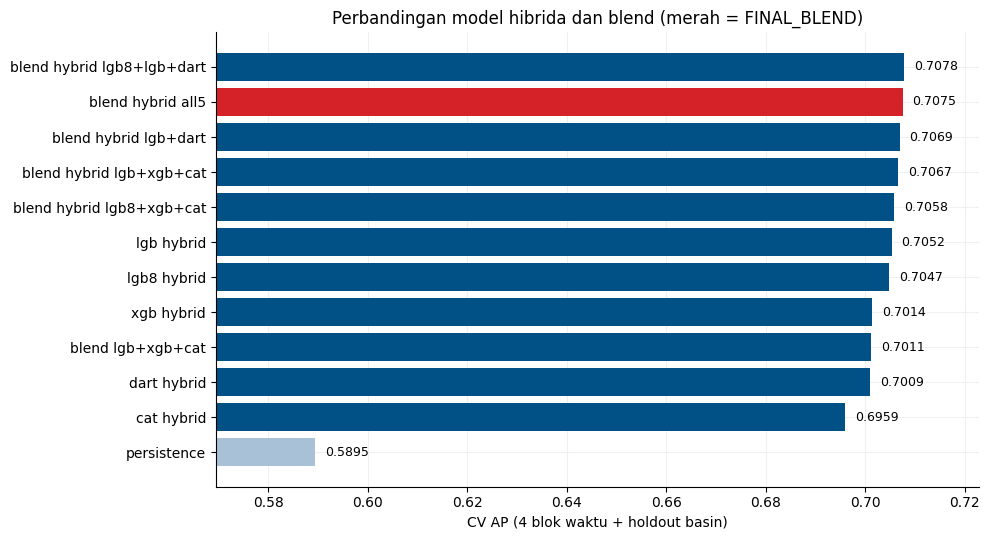

In [44]:
rank = lambda p: rankdata(p) / len(p)
oof['persistence'] = [-FOLD_X[i].anom0.fillna(0).values[va] for i, (_, va, _) in enumerate(FOLDS)]
BLENDS = {'blend lgb+xgb+cat': ['lgb', 'xgb', 'cat']}
if CFG.USE_TRANSITION:
    BLENDS['blend hybrid lgb8+xgb+cat'] = ['lgb8 hybrid', 'xgb hybrid', 'cat hybrid']
    BLENDS['blend hybrid lgb+xgb+cat'] = ['lgb hybrid', 'xgb hybrid', 'cat hybrid']
    BLENDS['blend hybrid lgb+dart'] = ['lgb hybrid', 'dart hybrid']
    BLENDS['blend hybrid lgb8+lgb+dart'] = ['lgb8 hybrid', 'lgb hybrid', 'dart hybrid']
    BLENDS['blend hybrid all5'] = ['lgb8 hybrid', 'lgb hybrid', 'dart hybrid', 'xgb hybrid', 'cat hybrid']
for b_, members_ in BLENDS.items():
    oof[b_] = [np.mean([rank(oof[k][i]) for k in members_], 0) for i in range(len(FOLDS))]

def test_like_ap(p, va, n_sets=200):
    rng = np.random.default_rng(CFG.SEED)
    d = pd.DataFrame({'o': train.origin_id.values[va], 'm': train.month.values[va], 'y': y[va], 'p': p})
    by_m = [d.o[d.m == m].unique() for m in (2, 4, 10, 12)]
    out = []
    for _ in range(n_sets):
        s = d[d.o.isin([rng.choice(o) for o in by_m if len(o)])]
        out.append(average_precision_score(s.y, s.p))
    return np.mean(out)

rows = []
for n, preds in oof.items():
    s = np.array([(average_precision_score(y[va], p),
                   average_precision_score(y[va][~uns[va]], p[~uns[va]]),
                   average_precision_score(y[va][uns[va]], p[uns[va]]))
                  for (trn, va, uns), p in zip(FOLDS, preds)])
    rows.append({'model': n, 'AP': s[:, 0].mean(), 'std': s[:, 0].std(), 'AP seen': s[:, 1].mean(),
                 'AP unseen': s[:, 2].mean(),
                 'test-like 4-origin AP': np.mean([test_like_ap(p, va) for (_, va, _), p in zip(FOLDS, preds)]),
                 **{f'fold{i}': v for i, v in enumerate(s[:, 0])}})
scores = pd.DataFrame(rows).set_index('model').sort_values('AP', ascending=False)
display(scores.round(4))

show = scores.loc[[k for k in scores.index if k.startswith('blend') or k.endswith('hybrid') or k == 'persistence']].AP.sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(show.index, show.values, color=[CFG.RED if k == CFG.FINAL_BLEND else CFG.LIGHT if k == 'persistence' else CFG.BLUE
                                        for k in show.index])
for i, v in enumerate(show.values):
    ax.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlim(show.min() - 0.02, show.max() + 0.015)
ax.set_xlabel('CV AP (4 blok waktu + holdout basin)')
ax.set_title('Perbandingan model hibrida dan blend (merah = FINAL_BLEND)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '17_model_scores.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Semua model *gradient boosting* jauh di atas *persistence* (sekitar 0.59), dan seluruh blend hibrida berada dalam selisih kurang dari 0.003 satu sama lain. Pada CV 4 blok ini selisih antar blend setara noise, sehingga pemilihan `FINAL_BLEND` tidak diambil dari tabel ini, melainkan dari validasi tiga split basin (subbagian Pemilihan Blend Final).
>
> Pipeline sudah dekat plafon informasi dataset. Model yang diberi fitur *oracle* (anomali bulan target dari sub-DAS lain pada basin dan waktu yang sama) mencapai AP 0.918 dibanding 0.690 tanpa *oracle*. Sisa kesalahan didominasi cuaca regional bulan depan yang tidak tersedia di *dataset*, bukan oleh rekayasa fitur yang kurang.

---

## Kurva Precision-Recall

Kurva PR blend final digambar per *fold* dan dibandingkan dengan *persistence*. Garis titik menandai prevalensi *fold*, yaitu AP tebakan acak.

Selected for submission: blend hybrid all5


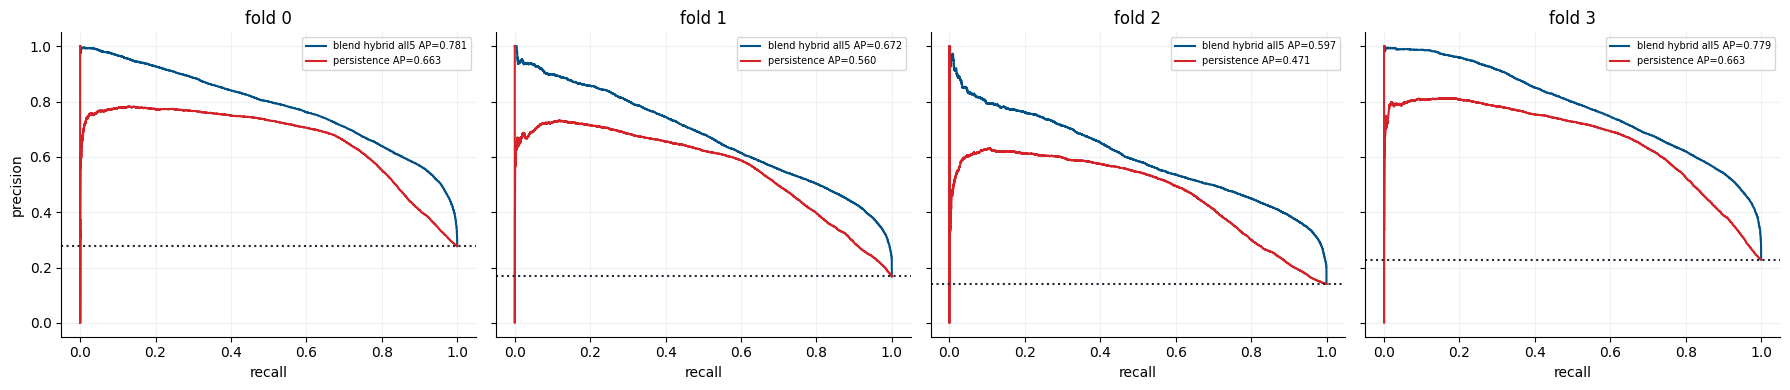

In [45]:
best_blend = CFG.FINAL_BLEND if CFG.FINAL_BLEND in oof else scores.loc[[k for k in scores.index if k in BLENDS]].AP.idxmax()
print('Selected for submission:', best_blend)
fig, axes = plt.subplots(1, len(FOLDS), figsize=(18, 4), sharey=True)
for i, ((trn, va, uns), ax) in enumerate(zip(FOLDS, axes)):
    for n, col in [(best_blend, CFG.BLUE), ('persistence', CFG.RED)]:
        pr, rc, _ = precision_recall_curve(y[va], oof[n][i])
        ax.plot(rc, pr, color=col, label=f'{n} AP={average_precision_score(y[va], oof[n][i]):.3f}')
    ax.axhline(y[va].mean(), ls=':', c=CFG.INK)
    ax.set_title(f'fold {i}')
    ax.set_xlabel('recall')
    ax.legend(fontsize=7)
axes[0].set_ylabel('precision')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '18_pr_curves.png', dpi=120, bbox_inches='tight')
plt.show()

---

## Analisis Kesalahan

AP dihitung ulang pada irisan data: jarak kondisi saat ini ke *threshold*, sub-DAS hulu, dan bulan *origin*. Irisan dengan AP rendah menunjukkan di mana model paling sering salah.

In [46]:
va_all = np.concatenate([np.where(va)[0] for _, va, _ in FOLDS])
p_all = np.concatenate([rank(p) for p in oof[best_blend]])
Xv = pd.concat([FOLD_X[i].iloc[np.where(va)[0]] for i, (_, va, _) in enumerate(FOLDS)])
err = pd.DataFrame({'y': y[va_all], 'p': p_all,
                    'dist': pd.cut((Xv.anom0.values - THR), [-np.inf, -1, -.3, 0, .3, 1, np.inf]),
                    'headwater': Xv.headwater.values, 'month': Xv.month.values})

def slice_ap(g):
    return pd.Series({'rows': len(g), 'pos_rate': g.y.mean(),
                      'AP': average_precision_score(g.y, g.p) if 0 < g.y.sum() < len(g) else np.nan})

for col in ['dist', 'headwater', 'month']:
    display(err.groupby(col, observed=True)[['y', 'p']].apply(slice_ap).round(3).T)

dist,"(-inf, -1.0]","(-1.0, -0.3]","(-0.3, 0.0]","(0.0, 0.3]","(0.3, 1.0]","(1.0, inf]"
rows,11882.000,31676.000,32087.000,50810.000,155348.000,86915.000
pos_rate,0.757,0.681,0.527,0.237,0.082,0.034
AP,0.864,0.837,0.707,0.454,0.287,0.197


headwater,0.0,1.0
rows,187286.000,181642.000
pos_rate,0.193,0.215
AP,0.696,0.703


month,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0
rows,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000,30744.000
pos_rate,0.214,0.201,0.206,0.206,0.205,0.187,0.184,0.177,0.215,0.219,0.216,0.214
AP,0.725,0.638,0.664,0.666,0.750,0.663,0.746,0.668,0.647,0.739,0.718,0.755


> ### Insights
> Kesalahan terkonsentrasi di dekat *threshold*. Baris yang saat ini sudah jauh di bawah *threshold* mencapai AP tinggi, sedangkan baris yang saat ini sedikit di atas *threshold* jauh lebih rendah. Kasus sulit adalah *onset* kekeringan: sub-DAS yang masih aman bulan ini tetapi jatuh di bawah 0.6 klimatologi bulan depan. Tanpa data curah hujan, *onset* hanya dapat ditebak dari tren, resesi *baseflow*, dan kondisi basin.
>
> Bulan *origin* di masa transisi musim lebih sulit daripada puncak musim, sejalan dengan *snowmelt* atau hujan musiman yang membuat pasokan bulan depan kurang dapat diprediksi dari persistensi.

---

## Audit Skema Validasi

CV notebook selalu sekitar 0.70, sedangkan *public score* sekitar 0.755. Untuk memastikan selisih ini bukan tanda *overfit* ke *public*, beberapa skema validasi dibandingkan pada model dan fitur yang sama. Fitur dibangun sekali dalam dua tampilan: tampilan *train* (sub-DAS yang dikenal, skala asli) dan tampilan validasi (semua sub-DAS, skala acak per sub-DAS, klimatologi hanya dari bulan 2, 4, 10, 12 seperti *test*). Model audit adalah XGBoost dengan 300 iterasi tetap, tanpa *early stopping* pada *fold* validasi.

In [47]:
rng = np.random.default_rng(CFG.SEED)
A_UNS = basin_holdout(train.id.values, rng)
seen_part = train[~A_UNS]
C_seen = clim_table(seen_part)
TV = add_discrete(build_features(seen_part, C_seen, BASIN))[FEATURES].astype('float32')
sv = rescale(train, seed=CFG.SEED + 100)
C_view = clim_table(sv[sv.month.isin([2, 4, 10, 12])], ref=C_seen)
VV = add_discrete(build_features(sv, C_view, BASIN))[FEATURES].astype('float32')
t_all, yr = train.t.values, train.t.values // 12

def audit_fit(fit, va, valid_view=True):
    fit = fit & ~A_UNS
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=7, min_child_weight=20, subsample=0.8,
                          colsample_bytree=0.6, reg_lambda=5.0, tree_method='hist', random_state=CFG.SEED,
                          device='cuda' if CFG.USE_GPU else 'cpu')
    m.fit(TV.loc[np.flatnonzero(fit)], y[fit], verbose=False)
    return m.predict_proba((VV if valid_view else TV).loc[np.flatnonzero(va)])[:, 1]

def run_audit(folds, valid_view=True):
    oof_a = np.full(len(train), np.nan)
    rows = []
    for fit, va in folds:
        va = va if valid_view else va & ~A_UNS
        oof_a[va] = audit_fit(fit, va, valid_view)
        rows.append({'prev': y[va].mean(), 'AP': average_precision_score(y[va], oof_a[va])})
    return oof_a, pd.DataFrame(rows)

def draws_4origin(oof_a, n=1000, seed=CFG.SEED):
    ok = ~np.isnan(oof_a)
    d = pd.DataFrame({'t': t_all[ok], 'm': train.month.values[ok], 'y': y[ok], 'p': oof_a[ok]})
    grp = dict(tuple(d.groupby('t')))
    by_m = {m: np.unique(d.t[d.m == m]) for m in (2, 4, 10, 12)}
    r, out = np.random.default_rng(seed), []
    while len(out) < n:
        pick = [r.choice(by_m[m]) for m in by_m]
        if min(abs(a - b) for i, a in enumerate(pick) for b in pick[i + 1:]) > 12:
            s_ = pd.concat([grp[k] for k in pick])
            out.append(average_precision_score(s_.y, s_.p))
    return np.array(out)

edges = np.linspace(t_all.min(), t_all.max() + 1, CFG.N_BLOCKS + 1).astype(int)
blocks = [((t_all < lo - CFG.PURGE) | (t_all >= hi + CFG.PURGE), (t_all >= lo) & (t_all < hi)) for lo, hi in zip(edges[:-1], edges[1:])]
rand = np.random.default_rng(CFG.SEED).integers(0, 5, len(train))
SCHEMES = {
    'random rows 5-fold (leaky)': ([(rand != k, rand == k) for k in range(5)], False),
    'time blocks + purge 12, seen HUCs': (blocks, False),
    'blocks + basin holdout + test view': (blocks, True),
    'forward, gap 12 (future only)': ([(t_all < 12 * k - 12, yr == k) for k in range(8, 14)], True),
    'leave-one-year-out, purge 12': ([((t_all < 12 * k - 12) | (t_all >= 12 * k + 24), yr == k) for k in range(14)], True),
}
audit, audit_oof, audit_tab = [], {}, {}
for name, (folds, view) in SCHEMES.items():
    o, tab = run_audit(folds, view)
    audit_oof[name], audit_tab[name] = o, tab
    tl = draws_4origin(o, 300) if view else np.array([np.nan])
    audit.append({'scheme': name, 'folds': len(folds), 'fold AP': tab.AP.mean(), 'fold std': tab.AP.std(),
                  'test-like AP': np.nanmean(tl)})
display(pd.DataFrame(audit).set_index('scheme').round(4))

,folds,fold AP,fold std,test-like AP
scheme,,,,
random rows 5-fold (leaky),5,0.8226,0.0023,NaN
"time blocks + purge 12, seen HUCs",4,0.6714,0.0964,NaN
blocks + basin holdout + test view,4,0.6846,0.0878,0.7152
"forward, gap 12 (future only)",6,0.6520,0.1488,0.7224
"leave-one-year-out, purge 12",14,0.6688,0.1186,0.7179


AP per tahun pada skema *leave-one-year-out* dibandingkan dengan prevalensi tahun tersebut, lalu distribusi AP undian 4 *origin* mirip *test* dibandingkan dengan *public score* notebook ini sebagai referensi (angka *public* hanya dipakai sebagai pembanding visual, tidak masuk ke perhitungan prediksi).

corr(year prevalence, AP) = 0.876; AP ~ 0.369 + 1.469 x prevalence
public reference 0.754 sits at percentile 72 of 4-origin draws (p10 0.631, median 0.720, p90 0.791)


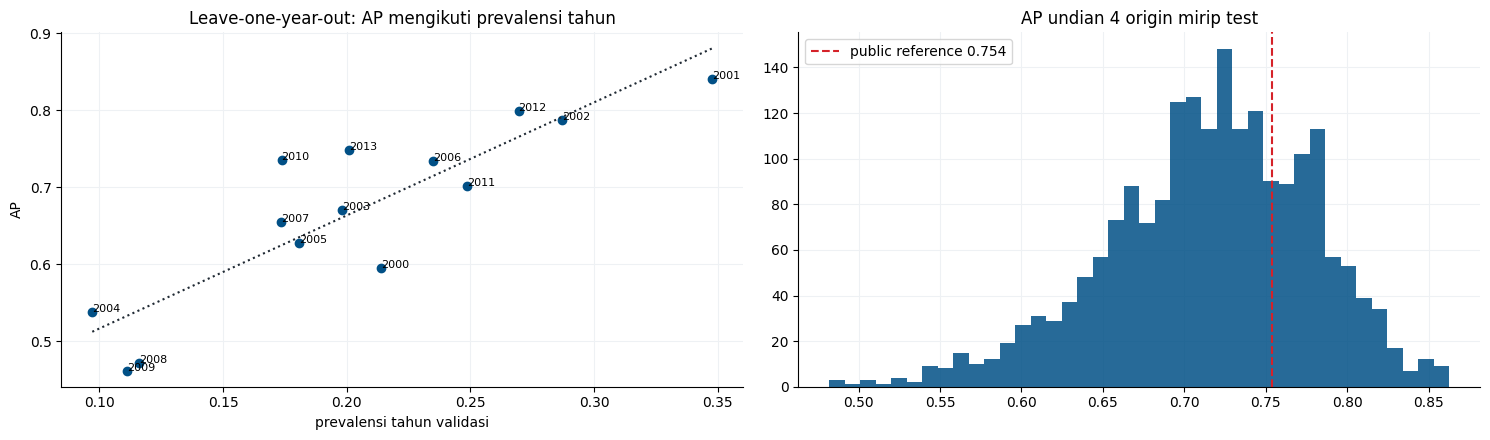

In [48]:
loyo = audit_tab['leave-one-year-out, purge 12'].assign(start=[date_of(12 * k) for k in range(14)])
slope, icpt = np.polyfit(loyo.prev, loyo.AP, 1)
r_prev = np.corrcoef(loyo.prev, loyo.AP)[0, 1]
draws = draws_4origin(audit_oof['leave-one-year-out, purge 12'], 2000)
PUBLIC_REF = 0.754
print(f'corr(year prevalence, AP) = {r_prev:.3f}; AP ~ {icpt:.3f} + {slope:.3f} x prevalence')
print(f'public reference {PUBLIC_REF} sits at percentile {100 * (draws < PUBLIC_REF).mean():.0f} of 4-origin draws '
      f'(p10 {np.percentile(draws, 10):.3f}, median {np.median(draws):.3f}, p90 {np.percentile(draws, 90):.3f})')
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].scatter(loyo.prev, loyo.AP, color=CFG.BLUE)
for _, r_ in loyo.iterrows():
    ax[0].annotate(r_.start[:4], (r_.prev, r_.AP), fontsize=8)
xx = np.linspace(loyo.prev.min(), loyo.prev.max(), 10)
ax[0].plot(xx, icpt + slope * xx, ':', color=CFG.INK)
ax[0].set_xlabel('prevalensi tahun validasi')
ax[0].set_ylabel('AP')
ax[0].set_title('Leave-one-year-out: AP mengikuti prevalensi tahun')
ax[1].hist(draws, bins=40, color=CFG.BLUE, alpha=.85)
ax[1].axvline(PUBLIC_REF, color=CFG.RED, ls='--', label=f'public reference {PUBLIC_REF}')
ax[1].legend()
ax[1].set_title('AP undian 4 origin mirip test')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '19_validation_audit.png', dpi=120, bbox_inches='tight')
plt.show()

> ### Insights
> Split baris acak memberi AP jauh lebih tinggi daripada skema yang meniru *test* (sekitar 14 poin). Kebocorannya berasal dari waktu: bulan yang sama muncul di sampai 12 baris lewat kolom lag, dan cuaca regional dibagi oleh semua sub-DAS pada bulan itu. *Purge* 12 bulan menutup sisa kebocoran di tepi blok, dan skala acak ditambah basin yang ditahan menurunkan lagi sekitar 0.8 poin.
>
> AP per tahun berkorelasi kuat dengan prevalensi tahun tersebut (sekitar 0.87). *Public score* berada di dalam sebaran undian 4 *origin* (sekitar persentil 70), sehingga selisih CV dan *public* bukan tanda *overfit* ke *public*, melainkan konsekuensi AP yang bergantung pada prevalensi: tahun *test* sedikit lebih kering dari rata-rata *train*.
>
> Skema maju (latih hanya di masa lalu) meniru posisi *test* secara langsung. AP tidak turun ketika jarak latih ke validasi diperpanjang, dan memakai seluruh masa lalu lebih baik daripada 8 atau 5 tahun terakhir. Tidak ada *concept drift*, sehingga model memakai seluruh 14 tahun tanpa pembobotan *recency*.

---

## Penjelasan Model Final

SHAP bawaan LightGBM dihitung pada sampel *test* untuk memastikan model final memakai sinyal yang masuk akal secara hidrologis. Fitur dikelompokkan menjadi 10 kelompok bermakna dalam 3 kategori: kondisi hidrologi sub-DAS, konteks wilayah dan waktu, serta pemakaian air.

features without a group: []


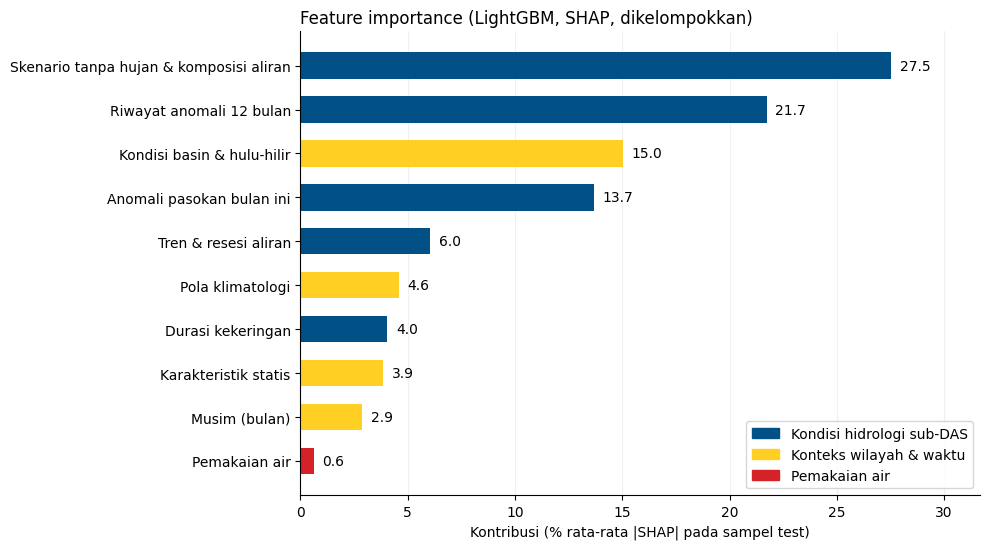

{'Kondisi hidrologi sub-DAS': np.float64(0.73), 'Konteks wilayah & waktu': np.float64(0.263), 'Pemakaian air': np.float64(0.006)}


In [49]:
GROUPS = {
    'Anomali pasokan bulan ini': ('hidro', ['anom0', 'margin_raw_persist']),
    'Riwayat anomali 12 bulan': ('hidro', [f'anom{k}' for k in range(1, 12)] + ['anom_mean3', 'anom_mean6', 'anom_mean12',
                                                                               'anom_min6', 'anom_std12']),
    'Durasi kekeringan': ('hidro', ['n_below12', 'drought_run']),
    'Skenario tanpa hujan & komposisi aliran': ('hidro', ['margin_dry', 'bf_share0', 'qf_share0', 'up_share0']),
    'Tren & resesi aliran': ('hidro', ['ws_trend1', 'ws_trend2', 'ws_trend3', 'bf_trend1', 'bf_recession', 'qf_mean3_share']),
    'Kondisi basin & hulu-hilir': ('konteks', ['down_anom0', 'up_anom0', 'basin_anom0', 'basin_below0', 'anom0_vs_basin']),
    'Musim (bulan)': ('konteks', ['month', 'm_sin', 'm_cos']),
    'Pola klimatologi': ('konteks', ['seas_step', 'clim_cv']),
    'Karakteristik statis': ('konteks', ['log_inc_area', 'log_cum_area', 'headwater', 'log_pop_dens', 'pop_growth']),
    'Pemakaian air': ('pakai', ['use_ratio0', 'use_clim_next', 'ir_share']),
}
CATS = {'hidro': ('Kondisi hidrologi sub-DAS', CFG.BLUE), 'konteks': ('Konteks wilayah & waktu', CFG.YELLOW),
        'pakai': ('Pemakaian air', CFG.RED)}

sample = X_test.sample(min(5000, len(X_test)), random_state=CFG.SEED)
contrib = pd.Series(np.abs(final_models['lgb'].predict(sample, pred_contrib=True)[:, :-1]).mean(0), FEATURES)
grouped = pd.Series({g: contrib.reindex(cols).sum() for g, (_, cols) in GROUPS.items()})
grouped = (grouped / grouped.sum()).sort_values()
print('features without a group:', sorted(set(FEATURES) - {c for _, cols in GROUPS.values() for c in cols}))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(grouped.index, grouped.values, height=0.6, color=[CATS[GROUPS[g][0]][1] for g in grouped.index])
for i, v in enumerate(grouped.values):
    ax.text(v + 0.004, i, f'{100 * v:.1f}', va='center', fontsize=10)
ax.set_xlim(0, grouped.max() * 1.15)
ax.xaxis.set_major_formatter(lambda v, _: f'{100 * v:.0f}')
ax.set_xlabel('Kontribusi (% rata-rata |SHAP| pada sampel test)')
ax.set_title('Feature importance (LightGBM, SHAP, dikelompokkan)', loc='left')
ax.grid(axis='y', visible=False)
ax.legend([Patch(color=c) for _, c in CATS.values()], [n for n, _ in CATS.values()], loc='lower right')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / '20_final_shap_grouped.png', dpi=120, bbox_inches='tight')
plt.show()
print({CATS[c][0]: round(grouped[[g for g, (cc, _) in GROUPS.items() if cc == c]].sum(), 3) for c in CATS})

> ### Insights
> Kondisi hidrologi sub-DAS itu sendiri (skenario tanpa hujan, riwayat anomali, anomali bulan ini) menyumbang sekitar tiga perempat keputusan model, diikuti kondisi basin dan hulu-hilir. Pemakaian air hanya berkontribusi di bawah 1 persen, konsisten dengan temuan EDA dan definisi label.
>
> Urutan ini masuk akal secara hidrologis: pasokan bulan depan ditentukan oleh posisi pasokan saat ini, memori air tanah (*baseflow*), dan cuaca regional yang tercermin pada sub-DAS tetangga.

---

## Pemilihan Blend Final

CV 4 blok di notebook ini terlalu kecil untuk membedakan blend (selisih di bawah 0.003). Pilihan `FINAL_BLEND` diambil dari run lokal yang lebih ketat: *leave-one-year-out* (14 tahun, *purge* 12 bulan) dengan holdout basin utuh, diulang pada tiga split basin berbeda (seed 42, 1, 7), lalu disimulasikan pada undian 4 *origin* mirip *test* yang barisnya dibagi acak menjadi *public* dan *private*.

| Kandidat | Gain vs blend lgb8+xgb+cat (split 42 / 1 / 7) | Naik di tahun | Undian *test-like* menang |
|---|---|---|---|
| lgb8+xgb+cat (konfigurasi V8) | 0 / 0 / 0 | - | - |
| lgb+xgb+cat | +0.0031 / +0.0017 / +0.0022 | 13, 11, 11 dari 14 | 70-79% |
| lgb+dart | +0.0060 / +0.0034 / +0.0039 | 13, 11, 10 | 77% |
| lgb8+lgb+dart | +0.0055 / +0.0035 / +0.0036 | 13, 13, 11 | 82% |
| **all5 (lgb8+lgb+dart+xgb+cat)** | **+0.0044 rata-rata, naik di 3/3 split** | - | **92%** |

> ### Insights
> Gain LightGBM hasil *tuning* (+0.0040) hanya muncul pada split basin tempat Optuna menyetel; pada dua split lain gain-nya hanya +0.0008 dan +0.0014. Memilih konfigurasi pada satu skema validasi ikut menghafal skema itu, sehingga keputusan final diambil dari rata-rata tiga split.
>
> Blend lima keluarga paling stabil: naik di ketiga split dan menang di 92 persen undian 4 *origin*. Pada *public*, blend ini (0.754) setara dengan konfigurasi V8 (0.75548); simulasi *public-private* menunjukkan keduanya memiliki perkiraan skor *private* yang sama, sehingga blend yang didukung validasi paling kuat yang dipilih.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Prediksi *test* dari model di dalam blend final digabung dengan rata-rata rank, lalu diskalakan ke rentang 0 sampai 1. AP hanya bergantung pada urutan skor, sehingga transformasi rank tidak mengubah skor dan menjaga format label tetap valid.

## Pembuatan Berkas Submisi

Submisi ditulis langsung dari prediksi model, lalu divalidasi terhadap format `sample_submission.csv`: setiap `row_id` muncul tepat satu kali dan tidak ada nilai kosong.

In [50]:
members = BLENDS.get(best_blend, [best_blend])
blend = np.mean([rank(test_pred[n]) for n in members], 0)
blend = (blend - blend.min()) / (blend.max() - blend.min())

submission = pd.DataFrame({'row_id': test.row_id.values, 'label': blend})
submission = sample_sub[['row_id']].merge(submission, on='row_id', how='left')
assert submission.label.notna().all(), 'Terdapat nilai kosong pada submisi'
assert submission.row_id.is_unique and len(submission) == len(sample_sub), 'row_id tidak sesuai sample_submission'
assert submission.label.between(0, 1).all(), 'Label di luar rentang 0-1'
submission.to_csv(CFG.SUBMISSION_CSV, index=False)
print('Blend members:', members)
print(f'Submisi disimpan ke {CFG.SUBMISSION_CSV} | bentuk {submission.shape}')
print(submission.describe().round(4).T)

per_origin = pd.DataFrame({'origin': test.origin_id.values, 'basin baru': ~seen_test, 'score': blend})
display(per_origin.groupby(['origin', 'basin baru']).score.mean().unstack().round(3))
submission.head()

Blend members: ['lgb8 hybrid', 'lgb hybrid', 'dart hybrid', 'xgb hybrid', 'cat hybrid']
Submisi disimpan ke /kaggle/working/submission.csv | bentuk (11928, 2)
          count       mean        std  min        25%        50%        75%  \
row_id  11928.0  5963.5000  3443.4613  0.0  2981.7500  5963.5000  8945.2500   
label   11928.0     0.4998     0.2873  0.0     0.2501     0.4995     0.7481   

            max  
row_id  11927.0  
label       1.0  


basin baru,False,True
origin,,
14,0.435,0.478
81,0.491,0.448
94,0.546,0.601
169,0.503,0.541


,row_id,label
0,0,0.406792
1,1,0.590373
2,2,0.669441
3,3,0.919732
4,4,0.467244


> ### Insights
> Skor submisi berada di rentang 0 sampai 1 dengan urutan identik dengan blend rank. Rata-rata skor per *origin* menunjukkan *origin* yang sedang lebih kering mendapat skor lebih tinggi, sesuai kondisi anomali saat ini pada data *test*.
>
> Submisi ini adalah keluaran langsung notebook: seluruh prediksi berasal dari model yang dilatih pada data *train* dengan fitur *test* yang dibangun tanpa label.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="11"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Perilaku Metrik dan Fair Play

AP dihitung atas gabungan empat *origin*, sehingga skor bergantung pada dua hal: urutan di dalam *origin* dan level skor antar *origin*. AP per tahun berkorelasi kuat dengan prevalensi tahun itu, dan menggeser tiap *origin* ke prevalensi aslinya (*oracle*) bernilai sekitar +0.025 AP. Informasi tersebut hanya bisa diperoleh dari label *test* (misalnya lewat *probing leaderboard*), sehingga tidak dipakai. Estimasi tanpa label (EM *label shift*, regresi agregat *origin*, koreksi level basin baru) sudah diuji dan tidak memperbaiki AP pada validasi.

---

## Hipotesis yang Diuji dan Ditolak

Beberapa ide yang benar secara teori ternyata gagal saat dievaluasi dengan skema yang meniru *test*, dan tidak dimasukkan ke notebook final:

| Ide | Teori | Hasil evaluasi |
|---|---|---|
| Fitur dinamika catchment | Autokorelasi dan *flashiness* menggambarkan sifat fisik sungai | Naik di holdout acak, turun -0.0017 di holdout basin (sidik jari wilayah) |
| *Target encoding* sub-DAS | Sub-DAS rawan cenderung rawan lagi | CV AP 0.7008 -> 0.5879 (menghafal identitas) |
| Regresi target kontinu | Target rasio lebih kaya daripada label biner | CV AP 0.6166, jauh di bawah klasifikasi |
| MLP dari nol | Arsitektur berbeda menambah keragaman ensemble | 7 sampai 10 poin di bawah GBDT, menurunkan blend |
| *Smoothing* prediksi ke rata-rata basin | Cuaca bersifat regional | AP selalu turun; model sudah memakai informasi basin |
| Augmentasi multi-*threshold* (0.45, 0.6, 0.8) | Lebih banyak contoh di dekat batas keputusan | +0.0014 total tetapi basin baru -0.0017 |
| Fitur jendela *origin test* berikutnya | Keempat *origin test* tampak membentuk rantai 14 bulan | CV +0.035, tetapi *public* turun 0.754 -> 0.733; bukti jaraknya terkontaminasi komponen anomali persisten per sub-DAS |

Kasus terakhir menjadi pelajaran utama: beberapa bukti yang berbagi *confounder* yang sama tidak boleh digabung seolah independen, dan setiap klaim tentang struktur *test* harus diuji dengan statistik yang kebal terhadap *confounder* tersebut.

---

### Kelebihan Pendekatan

Seluruh keputusan diambil dari validasi yang meniru *test* secara eksplisit: blok waktu dengan *purge*, holdout basin utuh, skala acak per sub-DAS, dan klimatologi yang hanya mengetahui 8 bulan. Fitur dibangun dari definisi fisik label (rasio pasokan terhadap klimatologi dan *threshold* 0.6), sehingga kebal terhadap korupsi skala di *test* dan mudah dijelaskan. Preprocessing diverifikasi terhadap *ground truth* lintas baris, bukan hanya lewat metrik model.

---

### Keterbatasan yang Diketahui

Sisa kesalahan terbesar adalah cuaca regional bulan depan yang tidak tersedia di *dataset* (plafon *oracle* 0.918 vs 0.690). *Onset* kekeringan pada sub-DAS yang masih aman bulan ini sulit diprediksi, dan level skor antar *origin* tidak dapat dikalibrasi tanpa informasi label *test*. Operasi GPU pada XGBoost dan CatBoost dapat memberi selisih urutan prediksi yang sangat kecil antar eksekusi.

---

### Arah Pengembangan Berikutnya

Jika data prakiraan cuaca atau indeks presipitasi diizinkan, fitur tersebut adalah kandidat paling bernilai karena langsung menyasar sisa kesalahan. Tanpa data tambahan, arah yang masih terbuka adalah model khusus zona *onset* dan evaluasi berbasis anggaran pemantauan (misalnya berapa persen kejadian tertangkap bila 20 persen sub-DAS dipantau setiap bulan).

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="12"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. KDD 2016. arXiv:1603.02754.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 2017.

Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS 2017. arXiv:1705.07874.

Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). *CatBoost: Unbiased Boosting with Categorical Features*. NeurIPS 2018. arXiv:1706.09516.

Rashmi, K. V., & Gilad-Bachrach, R. (2015). *DART: Dropouts meet Multiple Additive Regression Trees*. AISTATS 2015. arXiv:1505.01866.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schroder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*. Ecography, 40, 913-929.

U.S. Geological Survey (2025). *Integrated Water Availability Assessment, Conterminous United States: Surface Water Supply and Use Index (SUI)*. U.S. Geological Survey data release.

Frontiers in Water (2025). *Machine learning generated streamflow drought forecasts for the conterminous United States (CONUS)*. doi:10.3389/frwa.2025.1709138.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Thanks! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia **IFEST 2026 Final Data Analysis Competition** yang telah menyediakan *dataset* dan platform kompetisi yang menantang.